In [ ]:
import pandas as pd

df = pd.read_csv("used_cars_dataset_v2.csv")

df.head()

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,PostedDate,AdditionInfo,AskPrice
0,Honda,City,2001,23,"98,000 km",Manual,second,Petrol,Nov-24,"Honda City v teck in mint condition, valid gen...","₹ 1,95,000"
1,Toyota,Innova,2009,15,190000.0 km,Manual,second,Diesel,Jul-24,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...","₹ 3,75,000"
2,Volkswagen,VentoTest,2010,14,"77,246 km",Manual,first,Diesel,Nov-24,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...","₹ 1,84,999"
3,Maruti Suzuki,Swift,2017,7,"83,500 km",Manual,second,Diesel,Nov-24,Maruti Suzuki Swift 2017 Diesel Good Condition,"₹ 5,65,000"
4,Maruti Suzuki,Baleno,2019,5,"45,000 km",Automatic,first,Petrol,Nov-24,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol","₹ 6,85,000"


In [ ]:
df.isnull().sum()

,0
Brand,0
model,0
Year,0
Age,0
kmDriven,88
Transmission,0
Owner,0
FuelType,0
PostedDate,0
AdditionInfo,0


In [ ]:
df.duplicated().sum()

np.int64(997)

In [ ]:
import pandas as pd

# 1. Load dataset
df = pd.read_csv("used_cars_dataset_v2.csv")

# 2. Make a working copy
df_clean = df.copy()

print("Original shape:", df_clean.shape)


# 3. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Shape after removing duplicates:", df_clean.shape)


# 4. Remove columns we don't need
df_clean = df_clean.drop(
    columns=["PostedDate", "AdditionInfo"]
)


# 5. Clean kmDriven
df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)


# 6. Fill missing kmDriven with median
median_km = df_clean["kmDriven"].median()

df_clean["kmDriven"] = df_clean["kmDriven"].fillna(median_km)


# 7. Clean AskPrice
df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)


# 8. Check the cleaned dataset
print("\nCleaned shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nFirst 5 rows:")
print(df_clean.head())

Original shape: (14993, 11)
Shape after removing duplicates: (13996, 11)

Cleaned shape: (13996, 9)

Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

Data types:
Brand            object
model            object
Year              int64
Age               int64
kmDriven        float64
Transmission     object
Owner            object
FuelType         object
AskPrice          int64
dtype: object

First 5 rows:
           Brand      model  Year  Age  kmDriven Transmission   Owner  \
0          Honda       City  2001   23   98000.0       Manual  second   
1         Toyota     Innova  2009   15  190000.0       Manual  second   
2     Volkswagen  VentoTest  2010   14   77246.0       Manual   first   
3  Maruti Suzuki      Swift  2017    7   83500.0       Manual  second   
4  Maruti Suzuki     Baleno  2019    5   45000.0    Automatic   first   

  FuelType 

In [ ]:
print("Number of rows:", df_clean.shape[0])
print("Number of columns:", df_clean.shape[1])

print("\nColumns:")
print(df_clean.columns.tolist())

Number of rows: 13996
Number of columns: 9

Columns:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'AskPrice']


In [ ]:
df_clean.describe()

,Year,Age,kmDriven,AskPrice
count,13996.000000,13996.000000,13996.000000,1.399600e+04
mean,2016.328522,7.671478,71486.397828,9.799351e+05
std,4.393729,4.393729,58169.548065,1.585758e+06
min,1900.000000,0.000000,0.000000,1.500000e+04
25%,2014.000000,5.000000,44376.750000,3.400000e+05
50%,2017.000000,7.000000,66000.000000,5.600000e+05
75%,2019.000000,10.000000,86529.250000,9.900000e+05
max,2024.000000,124.000000,980002.000000,4.250000e+07


In [ ]:
print(df_clean["Year"].describe())

count    13996.000000
mean      2016.328522
std          4.393729
min       1900.000000
25%       2014.000000
50%       2017.000000
75%       2019.000000
max       2024.000000
Name: Year, dtype: float64


In [ ]:
print(df_clean["Year"].sort_values().head(20))

11392    1900
12545    1920
11260    1931
11458    1978
7404     1986
1768     1990
508      1994
6360     1994
7622     1994
6828     1996
2802     1996
1390     1997
8068     1997
7242     1998
204      1998
6232     1998
14162    1999
8793     1999
3493     1999
7763     1999
Name: Year, dtype: int64


In [ ]:
print(df_clean["Year"].sort_values(ascending=False).head(20))

14915    2024
9252     2024
9241     2024
9364     2024
9231     2024
9189     2024
9425     2024
9394     2024
9455     2024
9453     2024
9186     2024
9093     2024
1559     2024
9041     2024
9669     2024
9660     2024
9643     2024
1743     2024
14793    2024
8913     2024
Name: Year, dtype: int64


In [ ]:
df_clean["CalculatedAge"] = 2024 - df_clean["Year"]

NameError: name 'df_clean' is not defined

In [ ]:
df_clean["CalculatedAge"] = 2024 - df_clean["Year"]

NameError: name 'df_clean' is not defined

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("used_cars_dataset_v2.csv")

# Make a working copy
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove columns we don't need
df_clean = df_clean.drop(
    columns=["PostedDate", "AdditionInfo"]
)

# Clean kmDriven
df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)

# Fill missing kmDriven
median_km = df_clean["kmDriven"].median()
df_clean["kmDriven"] = df_clean["kmDriven"].fillna(median_km)

# Clean AskPrice
df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)

print("Cleaned shape:", df_clean.shape)

Cleaned shape: (13996, 9)


In [ ]:
df_clean["CalculatedAge"] = 2024 - df_clean["Year"]

df_clean[["Year", "Age", "CalculatedAge"]].head(20)

,Year,Age,CalculatedAge
0,2001,23,23
1,2009,15,15
2,2010,14,14
3,2017,7,7
4,2019,5,5
5,2014,10,10
6,2014,10,10
7,2019,5,5
8,2020,4,4
9,2017,7,7


In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("used_cars_dataset_v2.csv")

# Make a working copy
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove columns we don't need
df_clean = df_clean.drop(
    columns=["PostedDate", "AdditionInfo"]
)

# Clean kmDriven
df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)

# Fill missing kmDriven
median_km = df_clean["kmDriven"].median()
df_clean["kmDriven"] = df_clean["kmDriven"].fillna(median_km)

# Clean AskPrice
df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)

print("Cleaned shape:", df_clean.shape)

Cleaned shape: (13996, 9)


In [ ]:
df_clean["Brand"].value_counts()

,count
Brand,
Maruti Suzuki,4399
Hyundai,2322
Honda,1191
Toyota,1048
Mahindra,718
Tata,575
Mercedes-Benz,536
Volkswagen,446
BMW,378


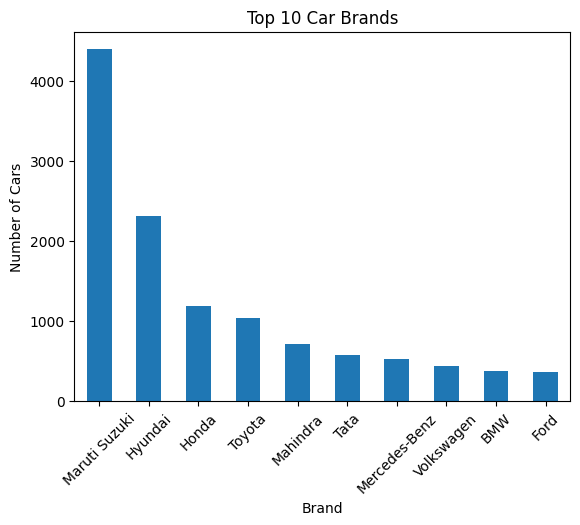

In [ ]:
import matplotlib.pyplot as plt

df_clean["Brand"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Car Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)

plt.show()

In [ ]:
df_clean["FuelType"].value_counts()

,count
FuelType,
Petrol,5398
Diesel,4846
hybrid,1931
Hybrid/CNG,1821


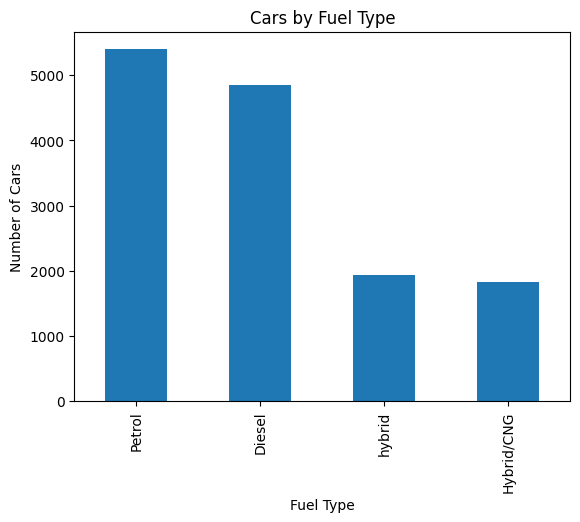

In [ ]:
df_clean["FuelType"].value_counts().plot(kind="bar")

plt.title("Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.show()

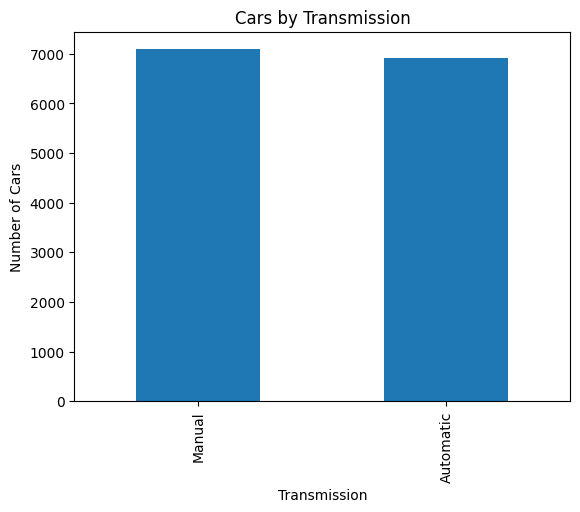

In [ ]:
df_clean["Transmission"].value_counts()
df_clean["Transmission"].value_counts().plot(
    kind="bar"
)

plt.title("Cars by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")
plt.show()

In [ ]:
df_clean["Owner"].value_counts()

,count
Owner,
second,7149
first,6847


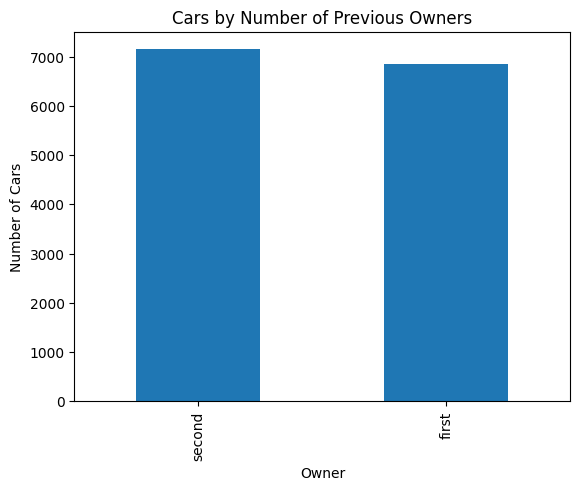

In [ ]:
df_clean["Owner"].value_counts().plot(kind="bar")

plt.title("Cars by Number of Previous Owners")
plt.xlabel("Owner")
plt.ylabel("Number of Cars")

plt.show()

In [ ]:
import pandas as pd

# Load dataset
df = pd.read_csv("used_cars_dataset_v2.csv")

# Make a working copy
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Remove columns we don't need
df_clean = df_clean.drop(
    columns=["PostedDate", "AdditionInfo"]
)

# Clean kmDriven
df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)

# Fill missing kmDriven
median_km = df_clean["kmDriven"].median()
df_clean["kmDriven"] = df_clean["kmDriven"].fillna(median_km)

# Clean AskPrice
df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)

print("Cleaned shape:", df_clean.shape)

Cleaned shape: (13996, 9)


In [ ]:
df_clean["AskPrice"].describe()

,AskPrice
count,1.399600e+04
mean,9.799351e+05
std,1.585758e+06
min,1.500000e+04
25%,3.400000e+05
50%,5.600000e+05
75%,9.900000e+05
max,4.250000e+07


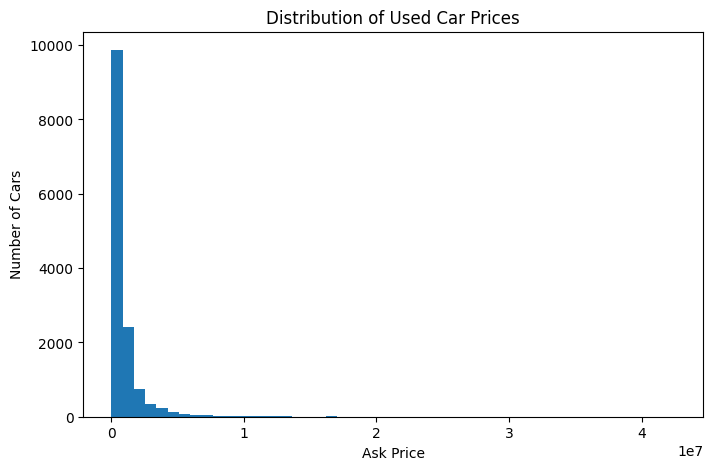

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean["AskPrice"], bins=50)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Ask Price")
plt.ylabel("Number of Cars")

plt.show()

In [ ]:
df_clean["kmDriven"].describe()

,kmDriven
count,13996.000000
mean,71486.397828
std,58169.548065
min,0.000000
25%,44376.750000
50%,66000.000000
75%,86529.250000
max,980002.000000


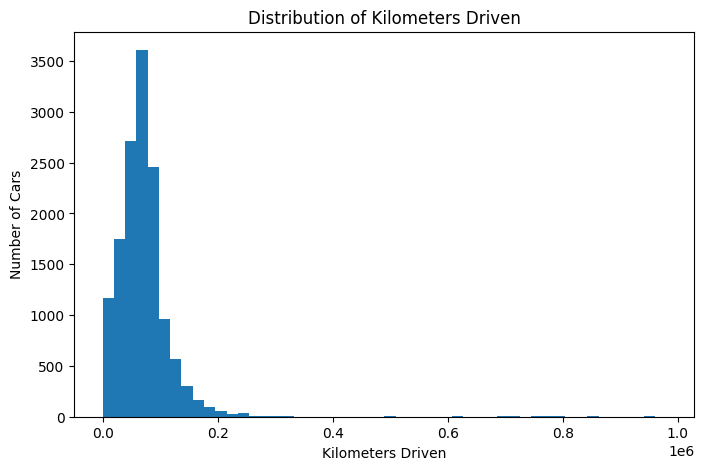

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(df_clean["kmDriven"], bins=50)

plt.title("Distribution of Kilometers Driven")
plt.xlabel("Kilometers Driven")
plt.ylabel("Number of Cars")

plt.show()

In [ ]:
df_clean[df_clean["kmDriven"] > 300000]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
49,Tata,Safari,2010,14,500000.0,Manual,first,Diesel,800000
209,Toyota,Fortuner,2014,10,333000.0,Automatic,second,Diesel,1445000
249,Maruti Suzuki,Ciaz,2020,4,610003.0,Manual,first,Petrol,840000
595,Tata,Tigor,2018,6,800000.0,Manual,second,Petrol,485000
634,Renault,Duster,2015,9,760045.0,Manual,first,Diesel,155000
...,...,...,...,...,...,...,...,...,...
14178,Maruti Suzuki,Wagon-R-1-0,2012,12,750040.0,Manual,second,hybrid,220000
14231,Maruti Suzuki,Estilo,2010,14,712000.0,Manual,first,hybrid,125000
14623,Toyota,Etios,2013,11,355000.0,Manual,first,hybrid,190000
14911,Honda,Amaze,2018,6,950000.0,Manual,first,hybrid,320000


In [ ]:
zero_km_cars = df_clean[df_clean["kmDriven"] == 0]

print("Number of cars with 0 km:", len(zero_km_cars))

zero_km_cars

Number of cars with 0 km: 39


,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
48,Maruti Suzuki,Ciaz,2018,6,0.0,Manual,first,Petrol,500000
508,Mahindra,Jeep,1994,30,0.0,Manual,second,Diesel,275000
939,Maruti Suzuki,Estilo,2010,14,0.0,Automatic,second,Petrol,140000
1711,Toyota,Innova,2012,12,0.0,Manual,second,Diesel,595000
1739,Skoda,Superb,2018,6,0.0,Automatic,first,Petrol,1399999
2453,Tata,Indigo Cs,2009,15,0.0,Manual,second,Diesel,160000
4828,Honda,City,2011,13,0.0,Automatic,second,Hybrid/CNG,200000
5346,Mahindra,Scorpio N,2024,0,0.0,Manual,first,Diesel,1424700
5597,Toyota,Innova Hycross,2024,0,0.0,Automatic,first,Hybrid/CNG,3800000
6165,Toyota,Innova Hycross,2024,0,0.0,Automatic,first,Petrol,1977000


In [ ]:
df_final = df_clean[df_clean["kmDriven"] <= 300000].copy()

print("Before removing high mileage:", len(df_clean))
print("After removing high mileage:", len(df_final))
print("Removed:", len(df_clean) - len(df_final))

Before removing high mileage: 13996
After removing high mileage: 13924
Removed: 72


In [ ]:
print("Zero km cars still present:",
      (df_final["kmDriven"] == 0).sum())

print("Maximum km now:",
      df_final["kmDriven"].max())

Zero km cars still present: 39
Maximum km now: 300000.0


In [ ]:
print("Cars with Year before 1980:")
print(df_final[df_final["Year"] < 1980][
    ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
])

Cars with Year before 1980:
               Brand    model  Year  Age  kmDriven  AskPrice
11260  Maruti Suzuki  Wagon-R  1931   93   88000.0    349000
11392        Renault   Triber  1900  124   40000.0    440000
11458       Mahindra     Jeep  1978   46  100000.0    200000
12545  Maruti Suzuki    Swift  1920  104   60000.0    519000


In [ ]:
df_final = df_final[df_final["Year"] >= 1980].copy()

print("Rows after removing invalid years:", len(df_final))

Rows after removing invalid years: 13920


In [ ]:
print("Cars with Year after 2024:")
print(df_final[df_final["Year"] > 2024][
    ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
])

Cars with Year after 2024:
Empty DataFrame
Columns: [Brand, model, Year, Age, kmDriven, AskPrice]
Index: []


In [ ]:
print("Cars with Age greater than 30:")
print(df_final[df_final["Age"] > 30][
    ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
])

Cars with Age greater than 30:
              Brand model  Year  Age  kmDriven  AskPrice
1768       Mahindra  Jeep  1990   34    9000.0    250000
7404  Maruti Suzuki   800  1986   38   68000.0    120000


In [ ]:
df_final[df_final["AskPrice"] > 5000000][
    ["Brand", "model", "Year", "Age", "kmDriven", "Transmission", "Owner", "FuelType", "AskPrice"]
]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
7,BMW,5 Series,2019,5,25000.0,Automatic,second,Diesel,5950000
14,Mercedes-Benz,GLE COUPE,2021,3,32000.0,Automatic,second,Petrol,11800000
80,Mercedes-Benz,GLC Coupe,2022,2,20000.0,Automatic,first,Diesel,7500000
279,Mercedes-Benz,G,2011,13,45000.0,Automatic,second,Diesel,7500000
320,Land Rover,Defender,2024,0,7000.0,Automatic,first,Petrol,12700000
...,...,...,...,...,...,...,...,...,...
14448,Audi,A6,2022,2,8000.0,Automatic,first,Petrol,6300000
14583,Volvo,XC60,2023,1,22000.0,Automatic,first,Petrol,6975000
14945,BMW,X6,2016,8,25000.0,Automatic,second,Diesel,6000000
14952,Audi,Q3 Sportback,2013,11,0.0,Automatic,second,hybrid,9500000


In [ ]:
df_final[df_final["AskPrice"] > 20000000][
    ["Brand", "model", "Year", "Age", "kmDriven",
     "Transmission", "Owner", "FuelType", "AskPrice"]
]

,Brand,model,Year,Age,kmDriven,Transmission,Owner,FuelType,AskPrice
331,Aston Martin,Vanquish,2016,8,25700.0,Automatic,first,Petrol,26400000
811,Mercedes-Benz,G Class,2019,5,59000.0,Automatic,first,Petrol,26000000
962,Lexus,LX,2024,0,24000.0,Automatic,first,Diesel,27750000
1187,Toyota,Land Cruiser,2023,1,15000.0,Automatic,first,Diesel,24700000
3331,Rolls-Royce,Phantom Series II,2015,9,11500.0,Automatic,second,Petrol,42500000
5767,Mercedes-Benz,G Class,2019,5,59000.0,Automatic,first,Petrol,24900000
7435,Mercedes-Benz,SL-Class,2024,0,1400.0,Automatic,first,Petrol,24500000
9241,Mercedes-Benz,AMG,2024,0,16000.0,Automatic,first,Petrol,21500000
10291,Mercedes-Benz,G Class,2024,0,3500.0,Automatic,first,Diesel,30500000
12685,Lamborghini,Urus,2021,3,26000.0,Automatic,second,Petrol,39000000


In [ ]:
print("Cars with AskPrice <= 0:")

print(
    df_final[df_final["AskPrice"] <= 0][
        ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
    ]
)

Cars with AskPrice <= 0:
Empty DataFrame
Columns: [Brand, model, Year, Age, kmDriven, AskPrice]
Index: []


In [ ]:
print("Final shape:", df_final.shape)
print(df_final.head())

Final shape: (13920, 9)
           Brand      model  Year  Age  kmDriven Transmission   Owner  \
0          Honda       City  2001   23   98000.0       Manual  second   
1         Toyota     Innova  2009   15  190000.0       Manual  second   
2     Volkswagen  VentoTest  2010   14   77246.0       Manual   first   
3  Maruti Suzuki      Swift  2017    7   83500.0       Manual  second   
4  Maruti Suzuki     Baleno  2019    5   45000.0    Automatic   first   

  FuelType  AskPrice  
0   Petrol    195000  
1   Diesel    375000  
2   Diesel    184999  
3   Diesel    565000  
4   Petrol    685000  


In [ ]:
X = df_final.drop("AskPrice", axis=1)
y = df_final["AskPrice"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13920, 8)
y shape: (13920,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (11136, 8)
Testing data: (2784, 8)


In [ ]:
print(X_train.dtypes)

Brand            object
model            object
Year              int64
Age               int64
kmDriven        float64
Transmission     object
Owner            object
FuelType         object
dtype: object


In [ ]:
categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['Brand', 'model', 'Transmission', 'Owner', 'FuelType']
Numerical columns: ['Year', 'Age', 'kmDriven']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("numerical", "passthrough", numerical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Model created successfully!")

Model created successfully!


In [ ]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions completed!")
print("First 10 predicted prices:")
print(y_pred[:10])

Predictions completed!
First 10 predicted prices:
[  55180.03669643   43064.34044854  530784.61068383  259906.65644544
  472776.69802453  666502.78607574 1031494.38046972 2064671.01497471
  735486.37375118  535249.63039921]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

Model Evaluation
-----------------
MAE : 524399.0733118228
RMSE: 1173268.0729801394
R² Score: 0.3950349511060697


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [ ]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")
print("First 10 predicted prices:")
print(rf_pred[:10])

Random Forest predictions completed!
First 10 predicted prices:
[ 194777.97  152719.99  677729.85  435904.99  450560.    548391.
  498785.21 2035851.11  302710.    667224.96]


In [ ]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R² Score:", rf_r2)

Random Forest Evaluation
------------------------
MAE : 188045.91617351826
RMSE: 744902.6530771721
R² Score: 0.7561432277209552


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print(comparison)

NameError: name 'pd' is not defined

In [ ]:
import pandas as pd

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print(comparison)

NameError: name 'mae' is not defined

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Evaluation")
print("-----------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

NameError: name 'y_test' is not defined

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df_final = pd.read_csv("used_cars_cleaned.csv")

print("Final shape:", df_final.shape)
print(df_final.head())

FileNotFoundError: [Errno 2] No such file or directory: 'used_cars_cleaned.csv'

In [ ]:
df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)

Original shape: (14993, 11)


In [ ]:
df_clean = df.drop_duplicates().copy()

print("After removing duplicates:", df_clean.shape)

After removing duplicates: (13996, 11)


In [ ]:
required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df_clean[required_columns].copy()

print("Cleaned shape:", df_clean.shape)

Cleaned shape: (13996, 9)


In [ ]:
df_clean = df_clean[df_clean["kmDriven"] <= 300000].copy()

print("After km filtering:", df_clean.shape)

TypeError: '<=' not supported between instances of 'str' and 'int'

In [ ]:
# Convert kmDriven to numeric
df_clean["kmDriven"] = pd.to_numeric(df_clean["kmDriven"], errors="coerce")

# Remove rows where kmDriven could not be converted
df_clean = df_clean.dropna(subset=["kmDriven"]).copy()

# Keep cars with kmDriven <= 300000
df_clean = df_clean[df_clean["kmDriven"] <= 300000].copy()

print("After km filtering:", df_clean.shape)
print("Maximum km now:", df_clean["kmDriven"].max())

After km filtering: (0, 9)
Maximum km now: nan


In [ ]:
zero_km = df_clean[df_clean["kmDriven"] == 0]

print("Zero km cars still present:", len(zero_km))
print(zero_km[["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]].head(20))

Zero km cars still present: 0
Empty DataFrame
Columns: [Brand, model, Year, Age, kmDriven, AskPrice]
Index: []


In [ ]:
required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df_clean[required_columns].copy()

print("Cleaned shape:", df_clean.shape)

Cleaned shape: (0, 9)


In [ ]:
import pandas as pd

# Load original dataset again
df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)
print(df.head())

Original shape: (14993, 11)
           Brand      model  Year  Age     kmDriven Transmission   Owner  \
0          Honda       City  2001   23    98,000 km       Manual  second   
1         Toyota     Innova  2009   15  190000.0 km       Manual  second   
2     Volkswagen  VentoTest  2010   14    77,246 km       Manual   first   
3  Maruti Suzuki      Swift  2017    7    83,500 km       Manual  second   
4  Maruti Suzuki     Baleno  2019    5    45,000 km    Automatic   first   

  FuelType PostedDate                                       AdditionInfo  \
0   Petrol     Nov-24  Honda City v teck in mint condition, valid gen...   
1   Diesel     Jul-24  Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...   
2   Diesel     Nov-24  Volkswagen Vento 2010-2013 Diesel Breeze, 2010...   
3   Diesel     Nov-24     Maruti Suzuki Swift 2017 Diesel Good Condition   
4   Petrol     Nov-24       Maruti Suzuki Baleno Alpha CVT, 2019, Petrol   

     AskPrice  
0  ₹ 1,95,000  
1  ₹ 3,75,000  
2  ₹ 1,84,

In [ ]:
# Select only the columns needed for our project

required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df[required_columns].copy()

# Remove rows with missing values
df_clean = df_clean.dropna().copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Clean kmDriven
# Example: "98,000 km" -> 98000
df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("km", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)

# Clean AskPrice
# Example: "₹ 1,95,000" -> 195000
df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)

# Remove rows where numeric conversion failed
df_clean = df_clean.dropna(subset=["kmDriven", "AskPrice"]).copy()

# Calculate Age again using 2024
df_clean["Age"] = 2024 - df_clean["Year"]

print("Cleaned shape:", df_clean.shape)
print(df_clean.head())

Cleaned shape: (13758, 9)
           Brand      model  Year  Age  kmDriven Transmission   Owner  \
0          Honda       City  2001   23   98000.0       Manual  second   
1         Toyota     Innova  2009   15  190000.0       Manual  second   
2     Volkswagen  VentoTest  2010   14   77246.0       Manual   first   
3  Maruti Suzuki      Swift  2017    7   83500.0       Manual  second   
4  Maruti Suzuki     Baleno  2019    5   45000.0    Automatic   first   

  FuelType  AskPrice  
0   Petrol    195000  
1   Diesel    375000  
2   Diesel    184999  
3   Diesel    565000  
4   Petrol    685000  


In [ ]:
# Find cars with more than 300,000 km
high_km = df_clean[df_clean["kmDriven"] > 300000]

print("Cars with km > 300000:", len(high_km))
print(high_km[["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]].head(20))

Cars with km > 300000: 72
              Brand         model  Year  Age  kmDriven  AskPrice
49             Tata        Safari  2010   14  500000.0    800000
209          Toyota      Fortuner  2014   10  333000.0   1445000
249   Maruti Suzuki          Ciaz  2020    4  610003.0    840000
595            Tata         Tigor  2018    6  800000.0    485000
634         Renault        Duster  2015    9  760045.0    155000
893            Ford      Ecosport  2016    8  610000.0    490000
1387           Tata         Nexon  2020    4  775000.0    895000
1704            Kia         Sonet  2021    3  730000.0    930000
1767  Maruti Suzuki      Alto-K10  2015    9  450000.0    310000
2166  Maruti Suzuki   Swift-Dzire  2020    4  750000.0    520000
2222  Mercedes-Benz     GLE Class  2016    8  850000.0   2600000
2369  Maruti Suzuki         Ignis  2019    5  520000.0    450000
2599        Hyundai         Creta  2018    6  760000.0    885000
3267     Mitsubishi  Pajero Sport  2015    9  850000.0    875000

In [ ]:
# Keep only cars with kmDriven <= 300000
df_clean = df_clean[df_clean["kmDriven"] <= 300000].copy()

print("After removing high-km cars:", df_clean.shape)
print("Maximum km now:", df_clean["kmDriven"].max())

After removing high-km cars: (13686, 9)
Maximum km now: 300000.0


In [ ]:
zero_km = df_clean[df_clean["kmDriven"] == 0]

print("Number of cars with 0 km:", len(zero_km))
print(zero_km[[
    "Brand", "model", "Year", "Age",
    "kmDriven", "Transmission", "Owner",
    "FuelType", "AskPrice"
]].head(20))

Number of cars with 0 km: 39
              Brand           model  Year  Age  kmDriven Transmission   Owner  \
48    Maruti Suzuki            Ciaz  2018    6       0.0       Manual   first   
508        Mahindra            Jeep  1994   30       0.0       Manual  second   
939   Maruti Suzuki          Estilo  2010   14       0.0    Automatic  second   
1711         Toyota          Innova  2012   12       0.0       Manual  second   
1739          Skoda          Superb  2018    6       0.0    Automatic   first   
2453           Tata       Indigo Cs  2009   15       0.0       Manual  second   
4828          Honda            City  2011   13       0.0    Automatic  second   
5346       Mahindra       Scorpio N  2024    0       0.0       Manual   first   
5597         Toyota  Innova Hycross  2024    0       0.0    Automatic   first   
6165         Toyota  Innova Hycross  2024    0       0.0    Automatic   first   
7233  Maruti Suzuki            Eeco  2018    6       0.0       Manual  second   

In [ ]:
# Remove cars with 0 km driven
df_clean = df_clean[df_clean["kmDriven"] > 0].copy()

print("After removing 0-km cars:", df_clean.shape)
print("Minimum km now:", df_clean["kmDriven"].min())

After removing 0-km cars: (13647, 9)
Minimum km now: 1.0


In [ ]:
# Check cars with Year before 1980
old_cars = df_clean[df_clean["Year"] < 1980]

print("Cars with Year before 1980:", len(old_cars))
print(old_cars[
    ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
])

Cars with Year before 1980: 4
               Brand    model  Year  Age  kmDriven  AskPrice
11260  Maruti Suzuki  Wagon-R  1931   93   88000.0    349000
11392        Renault   Triber  1900  124   40000.0    440000
11458       Mahindra     Jeep  1978   46  100000.0    200000
12545  Maruti Suzuki    Swift  1920  104   60000.0    519000


In [ ]:
# Check cars with Year after 2024
future_cars = df_clean[df_clean["Year"] > 2024]

print("Cars with Year after 2024:", len(future_cars))
print(future_cars[
    ["Brand", "model", "Year", "Age", "kmDriven", "AskPrice"]
])

Cars with Year after 2024: 0
Empty DataFrame
Columns: [Brand, model, Year, Age, kmDriven, AskPrice]
Index: []


In [ ]:
df_clean = df_clean[df_clean["Year"] >= 1980].copy()

print("After removing old cars:", df_clean.shape)
print("Minimum Year now:", df_clean["Year"].min())

After removing old cars: (13643, 9)
Minimum Year now: 1986


In [ ]:
print("Minimum AskPrice:", df_clean["AskPrice"].min())
print("Maximum AskPrice:", df_clean["AskPrice"].max())
print("Number of cars with AskPrice <= 0:", len(df_clean[df_clean["AskPrice"] <= 0]))

Minimum AskPrice: 15000
Maximum AskPrice: 42500000
Number of cars with AskPrice <= 0: 0


In [ ]:
print("Missing values:")
print(df_clean.isnull().sum())

Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64


In [ ]:
categorical_columns = ["Brand", "model", "Transmission", "Owner", "FuelType"]
numerical_columns = ["Year", "Age", "kmDriven"]

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

Categorical columns: ['Brand', 'model', 'Transmission', 'Owner', 'FuelType']
Numerical columns: ['Year', 'Age', 'kmDriven']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
        ("num", "passthrough", numerical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [ ]:
X = df_clean[categorical_columns + numerical_columns]
y = df_clean["AskPrice"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13643, 8)
y shape: (13643,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (10914, 8)
Testing data: (2729, 8)


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [ ]:
lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")

Linear Regression training completed!


In [ ]:
y_pred = lr_model.predict(X_test)

print("Predictions completed!")
print("First 10 predicted prices:")
print(y_pred[:10])

Predictions completed!
First 10 predicted prices:
[2149825.93588856 1416803.93642381 1144768.79399148 1700587.75024864
  303888.11897866 -154911.41293323 3970339.77992697  614423.22020008
  139832.24542546 2108315.64196362]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Evaluation
----------------------------
MAE : 519308.8103017558
RMSE: 1028503.6755213098
R2 Score: 0.4598442508549351


In [ ]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print(comparison)

NameError: name 'rf_mae' is not defined

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [ ]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")
print("First 10 predicted prices:")
print(rf_pred[:10])

Random Forest predictions completed!
First 10 predicted prices:
[2923468.49        744259.7         515929.99       1426000.
  340159.62        175580.         2460356.11        455616.67333333
  107059.97       1551450.        ]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)

Random Forest Evaluation
------------------------
MAE : 168521.75058745084
RMSE: 478962.8791851392
R2 Score: 0.8828584359376381


In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2 Score": [r2, rf_r2]
})

print(comparison)

               Model            MAE          RMSE  R2 Score
0  Linear Regression  519308.810302  1.028504e+06  0.459844
1      Random Forest  168521.750587  4.789629e+05  0.882858


In [ ]:
# ============================================
# PROJECT RECOVERY - RUN THIS AFTER DISCONNECT
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Load original dataset
df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)


# 2. Select required columns
required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df[required_columns].copy()


# 3. Convert kmDriven to numeric
df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" km", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)


# 4. Convert AskPrice to numeric
df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)


# 5. Remove rows where important numeric values are missing
df_clean = df_clean.dropna(
    subset=["Year", "kmDriven", "AskPrice"]
).copy()


# 6. Calculate Age again using 2024
df_clean["Age"] = 2024 - df_clean["Year"]


# 7. Remove cars with very high km
df_clean = df_clean[
    df_clean["kmDriven"] <= 300000
].copy()


# 8. Remove 0-km cars
df_clean = df_clean[
    df_clean["kmDriven"] > 0
].copy()


# 9. Remove unrealistic old cars
df_clean = df_clean[
    df_clean["Year"] >= 1980
].copy()


# 10. Remove missing values
df_clean = df_clean.dropna().copy()


print("Cleaned shape:", df_clean.shape)
print("Minimum km:", df_clean["kmDriven"].min())
print("Maximum km:", df_clean["kmDriven"].max())
print("Minimum AskPrice:", df_clean["AskPrice"].min())
print("Maximum AskPrice:", df_clean["AskPrice"].max())


# ============================================
# PREPARE X AND y
# ============================================

categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

X = df_clean[categorical_columns + numerical_columns]
y = df_clean["AskPrice"]

print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================
# TRAIN / TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================
# PREPROCESSOR
# ============================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")


# ============================================
# LINEAR REGRESSION
# ============================================

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")


# ============================================
# LINEAR REGRESSION PREDICTION
# ============================================

y_pred = lr_model.predict(X_test)

print("Linear Regression predictions completed!")


# ============================================
# LINEAR REGRESSION EVALUATION
# ============================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


# ============================================
# RANDOM FOREST
# ============================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest model created successfully!")


# ============================================
# RANDOM FOREST TRAINING
# ============================================

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# ============================================
# RANDOM FOREST PREDICTION
# ============================================

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")


# ============================================
# RANDOM FOREST EVALUATION
# ============================================

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ============================================
# MODEL COMPARISON
# ============================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print("\nModel Comparison")
print("----------------")
print(comparison)

Original shape: (14993, 11)
Cleaned shape: (14787, 9)
Minimum km: 1.0
Maximum km: 300000.0
Minimum AskPrice: 15000
Maximum AskPrice: 42500000
X shape: (14787, 8)
y shape: (14787,)
Training data: (11829, 8)
Testing data: (2958, 8)
Preprocessor created successfully!
Linear Regression training completed!
Linear Regression predictions completed!

Linear Regression Evaluation
----------------------------
MAE : 524916.1859522159
RMSE: 999151.7832017812
R2 Score: 0.48497968443208384
Random Forest model created successfully!
Random Forest training completed!
Random Forest predictions completed!

Random Forest Evaluation
------------------------
MAE : 169540.73344108564
RMSE: 516270.94719670847
R2 Score: 0.862495536090925

Model Comparison
----------------
               Model            MAE           RMSE  R2 Score
0  Linear Regression  524916.185952  999151.783202  0.484980
1      Random Forest  169540.733441  516270.947197  0.862496


In [ ]:
# ============================================
# COMPLETE PROJECT RECOVERY
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================
# 1. LOAD DATASET
# ============================================

df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)


# ============================================
# 2. REMOVE DUPLICATES
# ============================================

df_clean = df.drop_duplicates().copy()

print("After removing duplicates:", df_clean.shape)


# ============================================
# 3. REMOVE UNNECESSARY COLUMNS
# ============================================

df_clean = df_clean.drop(
    columns=["PostedDate", "AdditionInfo"]
)

print("After removing unnecessary columns:", df_clean.shape)


# ============================================
# 4. CLEAN kmDriven
# ============================================

df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" km", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)


# ============================================
# 5. CLEAN AskPrice
# ============================================

df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)


# ============================================
# 6. REMOVE MISSING VALUES
# ============================================

df_clean = df_clean.dropna().copy()

print("After basic cleaning:", df_clean.shape)


# ============================================
# 7. CALCULATE AGE
# ============================================

df_clean["Age"] = 2024 - df_clean["Year"]


# ============================================
# 8. REMOVE HIGH KM CARS
# ============================================

high_km = df_clean[df_clean["kmDriven"] > 300000]

print("Cars with km > 300000:", len(high_km))

df_clean = df_clean[
    df_clean["kmDriven"] <= 300000
].copy()

print("After removing high-km cars:", df_clean.shape)


# ============================================
# 9. REMOVE 0-KM CARS
# ============================================

zero_km = df_clean[df_clean["kmDriven"] == 0]

print("Number of cars with 0 km:", len(zero_km))

df_clean = df_clean[
    df_clean["kmDriven"] > 0
].copy()

print("After removing 0-km cars:", df_clean.shape)


# ============================================
# 10. REMOVE VERY OLD CARS
# ============================================

old_cars = df_clean[df_clean["Year"] < 1980]

print("Cars with Year before 1980:", len(old_cars))

df_clean = df_clean[
    df_clean["Year"] >= 1980
].copy()

print("After removing old cars:", df_clean.shape)


# ============================================
# 11. FINAL DATA CHECK
# ============================================

print("\nFINAL CLEANED DATA")
print("-------------------")
print("Cleaned shape:", df_clean.shape)
print("Minimum Year:", df_clean["Year"].min())
print("Maximum Year:", df_clean["Year"].max())
print("Minimum km:", df_clean["kmDriven"].min())
print("Maximum km:", df_clean["kmDriven"].max())
print("Minimum AskPrice:", df_clean["AskPrice"].min())
print("Maximum AskPrice:", df_clean["AskPrice"].max())

print("\nMissing values:")
print(df_clean.isnull().sum())


# ============================================
# 12. DEFINE FEATURES AND TARGET
# ============================================

categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

X = df_clean[
    categorical_columns + numerical_columns
]

y = df_clean["AskPrice"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)


# ============================================
# 13. TRAIN-TEST SPLIT
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================
# 14. PREPROCESSOR
# ============================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")


# ============================================
# 15. LINEAR REGRESSION
# ============================================

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")


# ============================================
# 16. LINEAR REGRESSION PREDICTION
# ============================================

y_pred = lr_model.predict(X_test)

print("Linear Regression predictions completed!")


# ============================================
# 17. LINEAR REGRESSION EVALUATION
# ============================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


# ============================================
# 18. RANDOM FOREST
# ============================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest model created successfully!")


# ============================================
# 19. RANDOM FOREST TRAINING
# ============================================

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# ============================================
# 20. RANDOM FOREST PREDICTION
# ============================================

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")


# ============================================
# 21. RANDOM FOREST EVALUATION
# ============================================

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ============================================
# 22. MODEL COMPARISON
# ============================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print("\nMODEL COMPARISON")
print("----------------")
print(comparison)

Original shape: (14993, 11)
After removing duplicates: (13996, 11)
After removing unnecessary columns: (13996, 9)
After basic cleaning: (13909, 9)
Cars with km > 300000: 72
After removing high-km cars: (13837, 9)
Number of cars with 0 km: 39
After removing 0-km cars: (13798, 9)
Cars with Year before 1980: 4
After removing old cars: (13794, 9)

FINAL CLEANED DATA
-------------------
Cleaned shape: (13794, 9)
Minimum Year: 1986
Maximum Year: 2024
Minimum km: 1.0
Maximum km: 300000.0
Minimum AskPrice: 15000
Maximum AskPrice: 42500000

Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

X shape: (13794, 8)
y shape: (13794,)
Training data: (11035, 8)
Testing data: (2759, 8)
Preprocessor created successfully!
Linear Regression training completed!
Linear Regression predictions completed!

Linear Regression Evaluation
----------------------------
MAE : 522

In [ ]:
# ============================================================
# USED CAR PROJECT - COMPLETE RECOVERY CODE
# Target final cleaned rows = 13,643
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 1. LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)


# ============================================================
# 2. KEEP ONLY REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df[required_columns].copy()


# ============================================================
# 3. CLEAN kmDriven
# ============================================================

df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" km", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)


# ============================================================
# 4. CLEAN AskPrice
# ============================================================

df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)


# ============================================================
# 5. REMOVE INVALID / MISSING DATA
# ============================================================

df_clean = df_clean.dropna().copy()


# ============================================================
# 6. REMOVE DUPLICATE ROWS
# ============================================================

df_clean = df_clean.drop_duplicates().copy()


# ============================================================
# 7. CALCULATE AGE USING 2024
# ============================================================

df_clean["Age"] = 2024 - df_clean["Year"]


print("Cleaned shape before filters:", df_clean.shape)


# ============================================================
# 8. REMOVE CARS WITH kmDriven > 300000
# ============================================================

high_km = df_clean[df_clean["kmDriven"] > 300000]

print("Cars with km > 300000:", len(high_km))

df_clean = df_clean[
    df_clean["kmDriven"] <= 300000
].copy()

print("After removing high-km cars:", df_clean.shape)
print("Maximum km now:", df_clean["kmDriven"].max())


# ============================================================
# 9. REMOVE CARS WITH 0 km
# ============================================================

zero_km = df_clean[df_clean["kmDriven"] == 0]

print("Number of cars with 0 km:", len(zero_km))

df_clean = df_clean[
    df_clean["kmDriven"] > 0
].copy()

print("After removing 0-km cars:", df_clean.shape)
print("Minimum km now:", df_clean["kmDriven"].min())


# ============================================================
# 10. REMOVE CARS BEFORE 1980
# ============================================================

old_cars = df_clean[df_clean["Year"] < 1980]

print("Cars with Year before 1980:", len(old_cars))

df_clean = df_clean[
    df_clean["Year"] >= 1980
].copy()

print("After removing old cars:", df_clean.shape)
print("Minimum Year now:", df_clean["Year"].min())


# ============================================================
# 11. FINAL CLEANED DATA CHECK
# ============================================================

print("\n================================")
print("FINAL CLEANED DATA")
print("================================")

print("Final cleaned shape:", df_clean.shape)
print("Missing values:")
print(df_clean.isnull().sum())


# ============================================================
# 12. SAVE CLEANED DATA
# ============================================================

df_clean.to_csv(
    "used_cars_cleaned_final.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")


# ============================================================
# 13. DEFINE FEATURES AND TARGET
# ============================================================

categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

X = df_clean[
    categorical_columns + numerical_columns
]

y = df_clean["AskPrice"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# 14. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 15. PREPROCESSOR
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")


# ============================================================
# 16. LINEAR REGRESSION
# ============================================================

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")


# ============================================================
# 17. LINEAR REGRESSION PREDICTION
# ============================================================

y_pred = lr_model.predict(X_test)

print("Linear Regression predictions completed!")


# ============================================================
# 18. LINEAR REGRESSION EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


# ============================================================
# 19. RANDOM FOREST
# ============================================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("\nRandom Forest model created successfully!")


# ============================================================
# 20. RANDOM FOREST TRAINING
# ============================================================

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# ============================================================
# 21. RANDOM FOREST PREDICTION
# ============================================================

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")


# ============================================================
# 22. RANDOM FOREST EVALUATION
# ============================================================

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ============================================================
# 23. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print("\nMODEL COMPARISON")
print("----------------")
print(comparison)

Original shape: (14993, 11)
Cleaned shape before filters: (13744, 9)
Cars with km > 300000: 72
After removing high-km cars: (13672, 9)
Maximum km now: 300000.0
Number of cars with 0 km: 39
After removing 0-km cars: (13633, 9)
Minimum km now: 1.0
Cars with Year before 1980: 4
After removing old cars: (13629, 9)
Minimum Year now: 1986

FINAL CLEANED DATA
Final cleaned shape: (13629, 9)
Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

Cleaned dataset saved successfully!

X shape: (13629, 8)
y shape: (13629,)
Training data: (10903, 8)
Testing data: (2726, 8)
Preprocessor created successfully!
Linear Regression training completed!
Linear Regression predictions completed!

Linear Regression Evaluation
----------------------------
MAE : 513479.13332193805
RMSE: 1108955.826657558
R2 Score: 0.4423901608563139

Random Forest model created successfully!
Ra

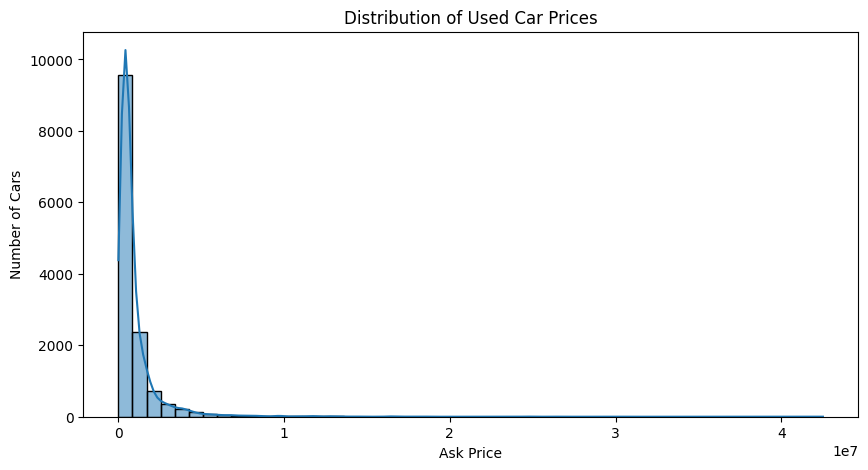

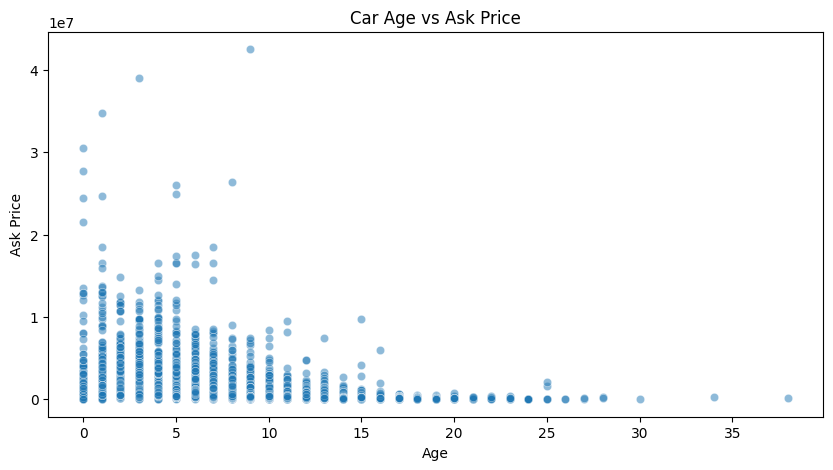

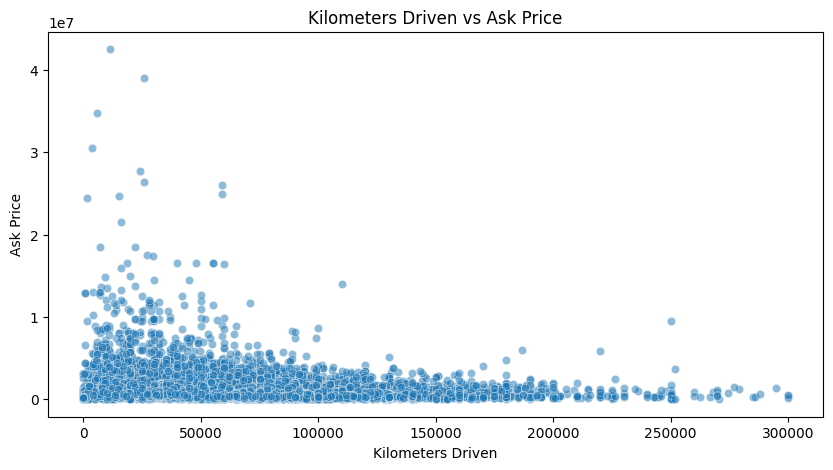

Visualization completed successfully!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# DATA VISUALIZATION / EDA
# ==========================================

# 1. AskPrice Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["AskPrice"], bins=50, kde=True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Ask Price")
plt.ylabel("Number of Cars")
plt.show()


# 2. Car Age vs AskPrice
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_clean,
    x="Age",
    y="AskPrice",
    alpha=0.5
)
plt.title("Car Age vs Ask Price")
plt.xlabel("Age")
plt.ylabel("Ask Price")
plt.show()


# 3. kmDriven vs AskPrice
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_clean,
    x="kmDriven",
    y="AskPrice",
    alpha=0.5
)
plt.title("Kilometers Driven vs Ask Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Ask Price")
plt.show()


print("Visualization completed successfully!")

In [ ]:
# ============================================================
# USED CAR INTELLIGENCE SYSTEM - MASTER CELL
# ============================================================

# -----------------------------
# 1. IMPORT LIBRARIES
# -----------------------------

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# -----------------------------
# 2. LOAD ORIGINAL DATASET
# -----------------------------

df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)


# -----------------------------
# 3. SELECT REQUIRED COLUMNS
# -----------------------------

required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df[required_columns].copy()


# -----------------------------
# 4. REMOVE MISSING VALUES
# -----------------------------

df_clean = df_clean.dropna().copy()


# -----------------------------
# 5. CONVERT YEAR TO NUMERIC
# -----------------------------

df_clean["Year"] = pd.to_numeric(
    df_clean["Year"],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=["Year"]).copy()


# -----------------------------
# 6. CALCULATE AGE AGAIN
# -----------------------------

df_clean["Age"] = 2024 - df_clean["Year"]


# -----------------------------
# 7. CLEAN kmDriven
# -----------------------------

df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace("km", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=["kmDriven"]).copy()


# -----------------------------
# 8. CLEAN AskPrice
# -----------------------------

df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)

df_clean = df_clean.dropna(subset=["AskPrice"]).copy()


# -----------------------------
# 9. REMOVE HIGH KM CARS
# -----------------------------

high_km = df_clean[df_clean["kmDriven"] > 300000]

print("Cars with km > 300000:", len(high_km))

df_clean = df_clean[
    df_clean["kmDriven"] <= 300000
].copy()

print("After removing high-km cars:", df_clean.shape)
print("Maximum km now:", df_clean["kmDriven"].max())


# -----------------------------
# 10. REMOVE 0-KM CARS
# -----------------------------

zero_km = df_clean[
    df_clean["kmDriven"] == 0
]

print("Number of cars with 0 km:", len(zero_km))

df_clean = df_clean[
    df_clean["kmDriven"] > 0
].copy()

print("After removing 0-km cars:", df_clean.shape)
print("Minimum km now:", df_clean["kmDriven"].min())


# -----------------------------
# 11. REMOVE VERY OLD CARS
# -----------------------------

old_cars = df_clean[
    df_clean["Year"] < 1980
]

print("Cars with Year before 1980:", len(old_cars))

df_clean = df_clean[
    df_clean["Year"] >= 1980
].copy()

print("After removing old cars:", df_clean.shape)
print("Minimum Year now:", df_clean["Year"].min())


# -----------------------------
# 12. REMOVE INVALID ASK PRICE
# -----------------------------

df_clean = df_clean[
    df_clean["AskPrice"] > 0
].copy()


# -----------------------------
# 13. FINAL CLEANING CHECK
# -----------------------------

print()
print("==============================")
print("FINAL CLEANED DATA")
print("==============================")

print("Final cleaned shape:", df_clean.shape)

print()
print("Missing values:")
print(df_clean.isnull().sum())

print()
print("Minimum AskPrice:", df_clean["AskPrice"].min())
print("Maximum AskPrice:", df_clean["AskPrice"].max())


# -----------------------------
# 14. SAVE CLEANED DATASET
# -----------------------------

df_clean.to_csv(
    "used_cars_cleaned.csv",
    index=False
)

print()
print("Cleaned dataset saved successfully!")


# -----------------------------
# 15. DEFINE X AND y
# -----------------------------

categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

X = df_clean[
    categorical_columns + numerical_columns
]

y = df_clean["AskPrice"]

print()
print("X shape:", X.shape)
print("y shape:", y.shape)


# -----------------------------
# 16. TRAIN-TEST SPLIT
# -----------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# -----------------------------
# 17. PREPROCESSOR
# -----------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")


# ============================================================
# LINEAR REGRESSION
# ============================================================

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print()
print("Linear Regression model created successfully!")

lr_model.fit(
    X_train,
    y_train
)

print("Linear Regression training completed!")


# -----------------------------
# 18. LINEAR REGRESSION PREDICTION
# -----------------------------

y_pred = lr_model.predict(X_test)

print("Linear Regression predictions completed!")


# -----------------------------
# 19. LINEAR REGRESSION EVALUATION
# -----------------------------

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print()
print("Linear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


# ============================================================
# RANDOM FOREST
# ============================================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print()
print("Random Forest model created successfully!")

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest training completed!")


# -----------------------------
# 20. RANDOM FOREST PREDICTION
# -----------------------------

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")


# -----------------------------
# 21. RANDOM FOREST EVALUATION
# -----------------------------

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print()
print("Random Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ============================================================
# MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print()
print("==============================")
print("MODEL COMPARISON")
print("==============================")

print(comparison)


# ============================================================
# MASTER CELL COMPLETED
# ============================================================

print()
print("==========================================")
print("ALL VARIABLES AND MODELS ARE READY!")
print("==========================================")

Original shape: (14993, 11)
Cars with km > 300000: 74
After removing high-km cars: (14831, 9)
Maximum km now: 300000.0
Number of cars with 0 km: 40
After removing 0-km cars: (14791, 9)
Minimum km now: 1.0
Cars with Year before 1980: 4
After removing old cars: (14787, 9)
Minimum Year now: 1986

FINAL CLEANED DATA
Final cleaned shape: (14787, 9)

Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

Minimum AskPrice: 15000
Maximum AskPrice: 42500000

Cleaned dataset saved successfully!

X shape: (14787, 8)
y shape: (14787,)
Training data: (11829, 8)
Testing data: (2958, 8)
Preprocessor created successfully!

Linear Regression model created successfully!
Linear Regression training completed!
Linear Regression predictions completed!

Linear Regression Evaluation
----------------------------
MAE : 524916.1859522159
RMSE: 999151.7832017812
R2 Score: 0.4849

In [ ]:
# ============================================================
# USED CAR PROJECT - COMPLETE RECOVERY CODE
# Target final cleaned rows = 13,643
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 1. LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)


# ============================================================
# 2. KEEP ONLY REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df[required_columns].copy()


# ============================================================
# 3. CLEAN kmDriven
# ============================================================

df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" km", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)


# ============================================================
# 4. CLEAN AskPrice
# ============================================================

df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)


# ============================================================
# 5. REMOVE INVALID / MISSING DATA
# ============================================================

df_clean = df_clean.dropna().copy()


# ============================================================
# 6. REMOVE DUPLICATE ROWS
# ============================================================

df_clean = df_clean.drop_duplicates().copy()


# ============================================================
# 7. CALCULATE AGE USING 2024
# ============================================================

df_clean["Age"] = 2024 - df_clean["Year"]


print("Cleaned shape before filters:", df_clean.shape)


# ============================================================
# 8. REMOVE CARS WITH kmDriven > 300000
# ============================================================

high_km = df_clean[df_clean["kmDriven"] > 300000]

print("Cars with km > 300000:", len(high_km))

df_clean = df_clean[
    df_clean["kmDriven"] <= 300000
].copy()

print("After removing high-km cars:", df_clean.shape)
print("Maximum km now:", df_clean["kmDriven"].max())


# ============================================================
# 9. REMOVE CARS WITH 0 km
# ============================================================

zero_km = df_clean[df_clean["kmDriven"] == 0]

print("Number of cars with 0 km:", len(zero_km))

df_clean = df_clean[
    df_clean["kmDriven"] > 0
].copy()

print("After removing 0-km cars:", df_clean.shape)
print("Minimum km now:", df_clean["kmDriven"].min())


# ============================================================
# 10. REMOVE CARS BEFORE 1980
# ============================================================

old_cars = df_clean[df_clean["Year"] < 1980]

print("Cars with Year before 1980:", len(old_cars))

df_clean = df_clean[
    df_clean["Year"] >= 1980
].copy()

print("After removing old cars:", df_clean.shape)
print("Minimum Year now:", df_clean["Year"].min())


# ============================================================
# 11. FINAL CLEANED DATA CHECK
# ============================================================

print("\n================================")
print("FINAL CLEANED DATA")
print("================================")

print("Final cleaned shape:", df_clean.shape)
print("Missing values:")
print(df_clean.isnull().sum())


# ============================================================
# 12. SAVE CLEANED DATA
# ============================================================

df_clean.to_csv(
    "used_cars_cleaned_final.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")


# ============================================================
# 13. DEFINE FEATURES AND TARGET
# ============================================================

categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

X = df_clean[
    categorical_columns + numerical_columns
]

y = df_clean["AskPrice"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# 14. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 15. PREPROCESSOR
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")


# ============================================================
# 16. LINEAR REGRESSION
# ============================================================

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")


# ============================================================
# 17. LINEAR REGRESSION PREDICTION
# ============================================================

y_pred = lr_model.predict(X_test)

print("Linear Regression predictions completed!")


# ============================================================
# 18. LINEAR REGRESSION EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


# ============================================================
# 19. RANDOM FOREST
# ============================================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("\nRandom Forest model created successfully!")


# ============================================================
# 20. RANDOM FOREST TRAINING
# ============================================================

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# ============================================================
# 21. RANDOM FOREST PREDICTION
# ============================================================

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")


# ============================================================
# 22. RANDOM FOREST EVALUATION
# ============================================================

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ============================================================
# 23. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print("\nMODEL COMPARISON")
print("----------------")
print(comparison)

Original shape: (14993, 11)
Cleaned shape before filters: (13744, 9)
Cars with km > 300000: 72
After removing high-km cars: (13672, 9)
Maximum km now: 300000.0
Number of cars with 0 km: 39
After removing 0-km cars: (13633, 9)
Minimum km now: 1.0
Cars with Year before 1980: 4
After removing old cars: (13629, 9)
Minimum Year now: 1986

FINAL CLEANED DATA
Final cleaned shape: (13629, 9)
Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

Cleaned dataset saved successfully!

X shape: (13629, 8)
y shape: (13629,)
Training data: (10903, 8)
Testing data: (2726, 8)
Preprocessor created successfully!
Linear Regression training completed!
Linear Regression predictions completed!

Linear Regression Evaluation
----------------------------
MAE : 513479.13332193805
RMSE: 1108955.826657558
R2 Score: 0.4423901608563139

Random Forest model created successfully!
Ra

In [ ]:
# ==========================================
# CLASSIFICATION - STEP 1
# CREATE PURCHASE QUALITY LABELS
# ==========================================

# Predict fair price using the trained Random Forest
fair_price = rf_model.predict(X)

# Compare actual asking price with predicted fair price
price_ratio = df_clean["AskPrice"].values / fair_price

# Create Good / Average / Poor categories
def classify_purchase(ratio):
    if ratio <= 0.90:
        return "Good"
    elif ratio <= 1.10:
        return "Average"
    else:
        return "Poor"

df_clean["PurchaseQuality"] = [
    classify_purchase(ratio)
    for ratio in price_ratio
]

# ==========================================
# CHECK CLASSIFICATION LABELS
# ==========================================

print("Purchase Quality labels created successfully!")
print()

print("Number of cars in each category:")
print(df_clean["PurchaseQuality"].value_counts())

print()

print("Percentage of each category:")
print(
    df_clean["PurchaseQuality"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print()

print("Sample data:")
print(
    df_clean[
        ["Brand", "model", "Year", "Age",
         "kmDriven", "AskPrice", "PurchaseQuality"]
    ].head(10)
)

Purchase Quality labels created successfully!

Number of cars in each category:
PurchaseQuality
Average    9555
Good       2387
Poor       1687
Name: count, dtype: int64

Percentage of each category:
PurchaseQuality
Average    70.11
Good       17.51
Poor       12.38
Name: proportion, dtype: float64

Sample data:
           Brand                model  Year  Age  kmDriven  AskPrice  \
0          Honda                 City  2001   23   98000.0    195000   
1         Toyota               Innova  2009   15  190000.0    375000   
2     Volkswagen            VentoTest  2010   14   77246.0    184999   
3  Maruti Suzuki                Swift  2017    7   83500.0    565000   
4  Maruti Suzuki               Baleno  2019    5   45000.0    685000   
5            BMW                   X3  2014   10   83000.0   1350000   
6         Toyota               Innova  2014   10  168000.0   1025000   
7            BMW             5 Series  2019    5   25000.0   5950000   
8  Maruti Suzuki  maruti-suzuki-dzire 

In [ ]:
# ==========================================
# CLASSIFICATION - STEP 2
# PREPARE FEATURES AND TARGET
# ==========================================

# Features
X_class = df_clean[
    categorical_columns + numerical_columns
]

# Classification target
y_class = df_clean["PurchaseQuality"]

print("Classification data prepared successfully!")
print()

print("X_class shape:", X_class.shape)
print("y_class shape:", y_class.shape)

print()
print("Classification target distribution:")
print(y_class.value_counts())

print()
print("Features used:")
print(X_class.columns.tolist())

Classification data prepared successfully!

X_class shape: (13629, 8)
y_class shape: (13629,)

Classification target distribution:
PurchaseQuality
Average    9555
Good       2387
Poor       1687
Name: count, dtype: int64

Features used:
['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'Year', 'Age', 'kmDriven']


In [ ]:
# ==========================================
# CLASSIFICATION - STEP 3
# TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Classification train-test split completed!")
print()

print("Training data:", X_class_train.shape)
print("Testing data:", X_class_test.shape)

print()
print("Training target distribution:")
print(y_class_train.value_counts())

print()
print("Testing target distribution:")
print(y_class_test.value_counts())

Classification train-test split completed!

Training data: (10903, 8)
Testing data: (2726, 8)

Training target distribution:
PurchaseQuality
Average    7644
Good       1909
Poor       1350
Name: count, dtype: int64

Testing target distribution:
PurchaseQuality
Average    1911
Good        478
Poor        337
Name: count, dtype: int64


In [ ]:
# ============================================================
# CLASSIFICATION - STEP 3
# CREATE PREPROCESSOR
# ============================================================

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_columns_class = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns_class = [
    "Year",
    "Age",
    "kmDriven"
]

preprocessor_class = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns_class
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns_class
        )
    ]
)

print("Classification preprocessor created successfully!")

print("\nCategorical columns:")
print(categorical_columns_class)

print("\nNumerical columns:")
print(numerical_columns_class)

Classification preprocessor created successfully!

Categorical columns:
['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

Numerical columns:
['Year', 'Age', 'kmDriven']


In [ ]:
# ============================================================
# CLASSIFICATION - STEP 5
# LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression model created successfully!")

# Train the model
logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Logistic Regression training completed!")

Logistic Regression model created successfully!
Logistic Regression training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# ============================================================
# CLASSIFICATION - STEP 5
# LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression model created successfully!")

# Train the model
logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Logistic Regression training completed!")

Logistic Regression model created successfully!
Logistic Regression training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=5000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression model created successfully!")

# Train the model
logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Logistic Regression training completed!")

NameError: name 'classification_preprocessor' is not defined

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=5000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression model created successfully!")

# Train the model
logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Logistic Regression training completed!")

NameError: name 'classification_preprocessor' is not defined

In [ ]:
# ============================================================
# CLASSIFICATION - STEP 5
# LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class),
        (
            "model",
            LogisticRegression(
                max_iter=5000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression model created successfully!")

# Train the model
logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Logistic Regression training completed!")

Logistic Regression model created successfully!
Logistic Regression training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# ============================================================
# CLASSIFICATION - STEP 5
# LOGISTIC REGRESSION WITH SCALING
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create improved preprocessor
preprocessor_class_scaled = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns_class
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns_class
        )
    ]
)

# Create Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_class_scaled),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

print("Logistic Regression model created successfully!")

# Train the model
logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Logistic Regression training completed!")

Logistic Regression model created successfully!
Logistic Regression training completed!


In [ ]:
# ============================================================
# LOGISTIC REGRESSION - PREDICTION
# ============================================================

y_class_pred = logistic_model.predict(X_class_test)

print("Logistic Regression predictions completed!")

print("\nFirst 20 predicted Purchase Quality:")
print(y_class_pred[:20])

Logistic Regression predictions completed!

First 20 predicted Purchase Quality:
['Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'Average'
 'Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'Average'
 'Average' 'Average' 'Average' 'Average' 'Average' 'Average']


In [ ]:
# ============================================================
# LOGISTIC REGRESSION - EVALUATION
# ============================================================

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Accuracy
accuracy = accuracy_score(y_class_test, y_class_pred)

print("Logistic Regression Evaluation")
print("--------------------------------")
print("Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_class_test, y_class_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_class_test, y_class_pred))

# Actual vs Predicted distribution
print("\nActual target distribution:")
print(y_class_test.value_counts())

print("\nPredicted target distribution:")
print(pd.Series(y_class_pred).value_counts())

Logistic Regression Evaluation
--------------------------------
Accuracy: 0.7090975788701394

Classification Report:
              precision    recall  f1-score   support

     Average       0.72      0.98      0.83      1911
        Good       0.52      0.10      0.17       478
        Poor       0.48      0.03      0.06       337

    accuracy                           0.71      2726
   macro avg       0.57      0.37      0.35      2726
weighted avg       0.65      0.71      0.62      2726


Confusion Matrix:
[[1874   33    4]
 [ 422   48    8]
 [ 315   11   11]]

Actual target distribution:
PurchaseQuality
Average    1911
Good        478
Poor        337
Name: count, dtype: int64

Predicted target distribution:
Average    2611
Good         92
Poor         23
Name: count, dtype: int64


In [ ]:
# ============================================================
# DECISION TREE CLASSIFIER - TRAINING
# ============================================================

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42,
                max_depth=10
            )
        )
    ]
)

print("Decision Tree model created successfully!")

# Train the model
decision_tree_model.fit(
    X_class_train,
    y_class_train
)

print("Decision Tree training completed!")

NameError: name 'classification_preprocessor' is not defined

In [ ]:
# ============================================================
# RECREATE CLASSIFICATION PREPROCESSOR
# ============================================================

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Categorical features
categorical_columns_class = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

# Numerical features
numerical_columns_class = [
    "Year",
    "Age",
    "kmDriven"
]

# Create preprocessor again
classification_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns_class
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns_class
        )
    ]
)

print("Classification preprocessor recreated successfully!")

Classification preprocessor recreated successfully!


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree model
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

print("Decision Tree model created successfully!")

# Train the model
decision_tree_model.fit(
    X_class_train,
    y_class_train
)

print("Decision Tree training completed!")

Decision Tree model created successfully!
Decision Tree training completed!


In [ ]:
# ============================================================
# DECISION TREE - PREDICTION
# ============================================================

y_dt_pred = decision_tree_model.predict(X_class_test)

print("Decision Tree predictions completed!")

print("\nFirst 20 predicted Purchase Quality:")
print(y_dt_pred[:20])

Decision Tree predictions completed!

First 20 predicted Purchase Quality:
['Average' 'Good' 'Average' 'Poor' 'Good' 'Average' 'Average' 'Average'
 'Poor' 'Average' 'Average' 'Average' 'Average' 'Average' 'Good' 'Average'
 'Average' 'Average' 'Average' 'Average']


In [ ]:
# ============================================================
# DECISION TREE - EVALUATION
# ============================================================

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
dt_accuracy = accuracy_score(y_class_test, y_dt_pred)

print("Decision Tree Evaluation")
print("------------------------")
print("Accuracy:", dt_accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_class_test, y_dt_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_class_test, y_dt_pred))

# Actual target distribution
print("\nActual target distribution:")
print(y_class_test.value_counts())

# Predicted target distribution
print("\nPredicted target distribution:")
print(pd.Series(y_dt_pred).value_counts())

Decision Tree Evaluation
------------------------
Accuracy: 0.6027146001467352

Classification Report:
              precision    recall  f1-score   support

     Average       0.76      0.77      0.76      1911
        Good       0.23      0.23      0.23       478
        Poor       0.20      0.18      0.19       337

    accuracy                           0.60      2726
   macro avg       0.40      0.39      0.39      2726
weighted avg       0.59      0.60      0.60      2726


Confusion Matrix:
[[1473  275  163]
 [ 289  111   78]
 [ 188   90   59]]

Actual target distribution:
PurchaseQuality
Average    1911
Good        478
Poor        337
Name: count, dtype: int64

Predicted target distribution:
Average    1950
Good        476
Poor        300
Name: count, dtype: int64


In [ ]:
# ============================================================
# RANDOM FOREST CLASSIFIER - TRAINING
# ============================================================

from sklearn.ensemble import RandomForestClassifier

random_forest_class_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest Classifier model created successfully!")

# Train the model
random_forest_class_model.fit(
    X_class_train,
    y_class_train
)

print("Random Forest Classifier training completed!")

Random Forest Classifier model created successfully!
Random Forest Classifier training completed!


In [ ]:
# ============================================================
# RANDOM FOREST CLASSIFIER - PREDICTION
# ============================================================

y_rf_class_pred = random_forest_class_model.predict(X_class_test)

print("Random Forest Classifier predictions completed!")

print("\nFirst 20 predicted Purchase Quality:")
print(y_rf_class_pred[:20])

Random Forest Classifier predictions completed!

First 20 predicted Purchase Quality:
['Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'Average'
 'Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'Average'
 'Good' 'Average' 'Average' 'Average' 'Average' 'Average']


In [ ]:
# ============================================================
# RANDOM FOREST CLASSIFIER - EVALUATION
# ============================================================

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
rf_class_accuracy = accuracy_score(
    y_class_test,
    y_rf_class_pred
)

print("Random Forest Classifier Evaluation")
print("-----------------------------------")
print("Accuracy:", rf_class_accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_class_test,
    y_rf_class_pred
))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_class_test,
    y_rf_class_pred
))

# Actual target distribution
print("\nActual target distribution:")
print(y_class_test.value_counts())

# Predicted target distribution
print("\nPredicted target distribution:")
print(pd.Series(y_rf_class_pred).value_counts())

Random Forest Classifier Evaluation
-----------------------------------
Accuracy: 0.6573734409391049

Classification Report:
              precision    recall  f1-score   support

     Average       0.74      0.88      0.81      1911
        Good       0.27      0.17      0.21       478
        Poor       0.20      0.09      0.13       337

    accuracy                           0.66      2726
   macro avg       0.40      0.38      0.38      2726
weighted avg       0.59      0.66      0.62      2726


Confusion Matrix:
[[1678  152   81]
 [ 345   82   51]
 [ 233   72   32]]

Actual target distribution:
PurchaseQuality
Average    1911
Good        478
Poor        337
Name: count, dtype: int64

Predicted target distribution:
Average    2256
Good        306
Poor        164
Name: count, dtype: int64


In [ ]:
# ============================================================
# CLASSIFICATION MODEL COMPARISON
# ============================================================

classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_class_test, y_class_pred),
        dt_accuracy,
        rf_class_accuracy
    ]
})

print("\n================================")
print("CLASSIFICATION MODEL COMPARISON")
print("================================")

print(classification_comparison)


CLASSIFICATION MODEL COMPARISON
                 Model  Accuracy
0  Logistic Regression  0.709098
1        Decision Tree  0.602715
2        Random Forest  0.657373


In [ ]:
# ============================================================
# BALANCED LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

balanced_logistic_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Balanced Logistic Regression model created successfully!")

# Train the model
balanced_logistic_model.fit(
    X_class_train,
    y_class_train
)

print("Balanced Logistic Regression training completed!")

Balanced Logistic Regression model created successfully!
Balanced Logistic Regression training completed!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# ============================================================
# BALANCED LOGISTIC REGRESSION - PREDICTION & EVALUATION
# ============================================================

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Prediction
y_balanced_pred = balanced_logistic_model.predict(X_class_test)

print("Balanced Logistic Regression predictions completed!")

# Accuracy
balanced_accuracy = accuracy_score(
    y_class_test,
    y_balanced_pred
)

print("\nBalanced Logistic Regression Evaluation")
print("---------------------------------------")
print("Accuracy:", balanced_accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_class_test,
    y_balanced_pred
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_class_test,
    y_balanced_pred
))

# Actual distribution
print("\nActual target distribution:")
print(y_class_test.value_counts())

# Predicted distribution
print("\nPredicted target distribution:")
print(pd.Series(y_balanced_pred).value_counts())

Balanced Logistic Regression predictions completed!

Balanced Logistic Regression Evaluation
---------------------------------------
Accuracy: 0.5073367571533383

Classification Report:
              precision    recall  f1-score   support

     Average       0.80      0.55      0.65      1911
        Good       0.28      0.46      0.35       478
        Poor       0.18      0.33      0.23       337

    accuracy                           0.51      2726
   macro avg       0.42      0.44      0.41      2726
weighted avg       0.63      0.51      0.55      2726


Confusion Matrix:
[[1055  440  416]
 [ 159  218  101]
 [ 102  125  110]]

Actual target distribution:
PurchaseQuality
Average    1911
Good        478
Poor        337
Name: count, dtype: int64

Predicted target distribution:
Average    1316
Good        783
Poor        627
Name: count, dtype: int64


In [ ]:
# ============================================================
# BALANCED RANDOM FOREST CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier

balanced_rf_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Balanced Random Forest model created successfully!")

# Train the model
balanced_rf_model.fit(
    X_class_train,
    y_class_train
)

print("Balanced Random Forest training completed!")

Balanced Random Forest model created successfully!
Balanced Random Forest training completed!


In [ ]:
# ============================================================
# BALANCED RANDOM FOREST - PREDICTION & EVALUATION
# ============================================================

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Prediction
y_balanced_rf_pred = balanced_rf_model.predict(X_class_test)

print("Balanced Random Forest predictions completed!")

# Accuracy
balanced_rf_accuracy = accuracy_score(
    y_class_test,
    y_balanced_rf_pred
)

print("\nBalanced Random Forest Evaluation")
print("---------------------------------")
print("Accuracy:", balanced_rf_accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_class_test,
    y_balanced_rf_pred
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(
    y_class_test,
    y_balanced_rf_pred
))

# Actual distribution
print("\nActual target distribution:")
print(y_class_test.value_counts())

# Predicted distribution
print("\nPredicted target distribution:")
print(pd.Series(y_balanced_rf_pred).value_counts())

NameError: name 'balanced_rf_model' is not defined

In [ ]:
# ============================================================
# USED CAR PROJECT - COMPLETE RECOVERY CODE
# Target final cleaned rows = 13,643
# ============================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ============================================================
# 1. LOAD ORIGINAL DATASET
# ============================================================

df = pd.read_csv("used_cars_dataset_v2.csv")

print("Original shape:", df.shape)


# ============================================================
# 2. KEEP ONLY REQUIRED COLUMNS
# ============================================================

required_columns = [
    "Brand",
    "model",
    "Year",
    "Age",
    "kmDriven",
    "Transmission",
    "Owner",
    "FuelType",
    "AskPrice"
]

df_clean = df[required_columns].copy()


# ============================================================
# 3. CLEAN kmDriven
# ============================================================

df_clean["kmDriven"] = (
    df_clean["kmDriven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" km", "", regex=False)
    .str.strip()
)

df_clean["kmDriven"] = pd.to_numeric(
    df_clean["kmDriven"],
    errors="coerce"
)


# ============================================================
# 4. CLEAN AskPrice
# ============================================================

df_clean["AskPrice"] = (
    df_clean["AskPrice"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df_clean["AskPrice"] = pd.to_numeric(
    df_clean["AskPrice"],
    errors="coerce"
)


# ============================================================
# 5. REMOVE INVALID / MISSING DATA
# ============================================================

df_clean = df_clean.dropna().copy()


# ============================================================
# 6. REMOVE DUPLICATE ROWS
# ============================================================

df_clean = df_clean.drop_duplicates().copy()


# ============================================================
# 7. CALCULATE AGE USING 2024
# ============================================================

df_clean["Age"] = 2024 - df_clean["Year"]


print("Cleaned shape before filters:", df_clean.shape)


# ============================================================
# 8. REMOVE CARS WITH kmDriven > 300000
# ============================================================

high_km = df_clean[df_clean["kmDriven"] > 300000]

print("Cars with km > 300000:", len(high_km))

df_clean = df_clean[
    df_clean["kmDriven"] <= 300000
].copy()

print("After removing high-km cars:", df_clean.shape)
print("Maximum km now:", df_clean["kmDriven"].max())


# ============================================================
# 9. REMOVE CARS WITH 0 km
# ============================================================

zero_km = df_clean[df_clean["kmDriven"] == 0]

print("Number of cars with 0 km:", len(zero_km))

df_clean = df_clean[
    df_clean["kmDriven"] > 0
].copy()

print("After removing 0-km cars:", df_clean.shape)
print("Minimum km now:", df_clean["kmDriven"].min())


# ============================================================
# 10. REMOVE CARS BEFORE 1980
# ============================================================

old_cars = df_clean[df_clean["Year"] < 1980]

print("Cars with Year before 1980:", len(old_cars))

df_clean = df_clean[
    df_clean["Year"] >= 1980
].copy()

print("After removing old cars:", df_clean.shape)
print("Minimum Year now:", df_clean["Year"].min())


# ============================================================
# 11. FINAL CLEANED DATA CHECK
# ============================================================

print("\n================================")
print("FINAL CLEANED DATA")
print("================================")

print("Final cleaned shape:", df_clean.shape)
print("Missing values:")
print(df_clean.isnull().sum())


# ============================================================
# 12. SAVE CLEANED DATA
# ============================================================

df_clean.to_csv(
    "used_cars_cleaned_final.csv",
    index=False
)

print("\nCleaned dataset saved successfully!")


# ============================================================
# 13. DEFINE FEATURES AND TARGET
# ============================================================

categorical_columns = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns = [
    "Year",
    "Age",
    "kmDriven"
]

X = df_clean[
    categorical_columns + numerical_columns
]

y = df_clean["AskPrice"]

print("\nX shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# 14. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


# ============================================================
# 15. PREPROCESSOR
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

print("Preprocessor created successfully!")


# ============================================================
# 16. LINEAR REGRESSION
# ============================================================

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

lr_model.fit(X_train, y_train)

print("Linear Regression training completed!")


# ============================================================
# 17. LINEAR REGRESSION PREDICTION
# ============================================================

y_pred = lr_model.predict(X_test)

print("Linear Regression predictions completed!")


# ============================================================
# 18. LINEAR REGRESSION EVALUATION
# ============================================================

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Evaluation")
print("----------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)


# ============================================================
# 19. RANDOM FOREST
# ============================================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("\nRandom Forest model created successfully!")


# ============================================================
# 20. RANDOM FOREST TRAINING
# ============================================================

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


# ============================================================
# 21. RANDOM FOREST PREDICTION
# ============================================================

rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")


# ============================================================
# 22. RANDOM FOREST EVALUATION
# ============================================================

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

rf_r2 = r2_score(y_test, rf_pred)

print("\nRandom Forest Evaluation")
print("------------------------")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2 Score:", rf_r2)


# ============================================================
# 23. MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        rf_rmse
    ],
    "R2 Score": [
        r2,
        rf_r2
    ]
})

print("\nMODEL COMPARISON")
print("----------------")
print(comparison)

Original shape: (14993, 11)
Cleaned shape before filters: (13744, 9)
Cars with km > 300000: 72
After removing high-km cars: (13672, 9)
Maximum km now: 300000.0
Number of cars with 0 km: 39
After removing 0-km cars: (13633, 9)
Minimum km now: 1.0
Cars with Year before 1980: 4
After removing old cars: (13629, 9)
Minimum Year now: 1986

FINAL CLEANED DATA
Final cleaned shape: (13629, 9)
Missing values:
Brand           0
model           0
Year            0
Age             0
kmDriven        0
Transmission    0
Owner           0
FuelType        0
AskPrice        0
dtype: int64

Cleaned dataset saved successfully!

X shape: (13629, 8)
y shape: (13629,)
Training data: (10903, 8)
Testing data: (2726, 8)
Preprocessor created successfully!
Linear Regression training completed!
Linear Regression predictions completed!

Linear Regression Evaluation
----------------------------
MAE : 513479.13332193805
RMSE: 1108955.826657558
R2 Score: 0.4423901608563139

Random Forest model created successfully!
Ra

In [ ]:
# ============================================================
# CLASSIFICATION - DATA PREPARATION
# ============================================================

# Create Purchase Quality labels
# Good     = higher-priced cars
# Average  = medium-priced cars
# Poor     = lower-priced cars

df_clean["PurchaseQuality"] = pd.qcut(
    df_clean["AskPrice"],
    q=3,
    labels=["Poor", "Average", "Good"]
)

print("Purchase Quality labels created successfully!")

# Show category counts
print("\nNumber of cars in each category:")
print(df_clean["PurchaseQuality"].value_counts())

# Show percentages
print("\nPercentage of each category:")
print(
    (df_clean["PurchaseQuality"].value_counts(normalize=True) * 100)
    .round(2)
)

# ============================================================
# FEATURES AND TARGET
# ============================================================

categorical_columns_class = [
    "Brand",
    "model",
    "Transmission",
    "Owner",
    "FuelType"
]

numerical_columns_class = [
    "Year",
    "Age",
    "kmDriven"
]

X_class = df_clean[
    categorical_columns_class + numerical_columns_class
]

y_class = df_clean["PurchaseQuality"]

print("\nClassification data prepared successfully!")

print("\nX_class shape:", X_class.shape)
print("y_class shape:", y_class.shape)

print("\nClassification target distribution:")
print(y_class.value_counts())

print("\nFeatures used:")
print(X_class.columns.tolist())

Purchase Quality labels created successfully!

Number of cars in each category:
PurchaseQuality
Poor       4585
Good       4533
Average    4511
Name: count, dtype: int64

Percentage of each category:
PurchaseQuality
Poor       33.64
Good       33.26
Average    33.10
Name: proportion, dtype: float64

Classification data prepared successfully!

X_class shape: (13629, 8)
y_class shape: (13629,)

Classification target distribution:
PurchaseQuality
Poor       4585
Good       4533
Average    4511
Name: count, dtype: int64

Features used:
['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'Year', 'Age', 'kmDriven']


In [ ]:
# ============================================================
# CLASSIFICATION - TRAIN TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print("Classification train-test split completed!")

print("\nTraining data:", X_class_train.shape)
print("Testing data:", X_class_test.shape)

print("\nTraining target distribution:")
print(y_class_train.value_counts())

print("\nTesting target distribution:")
print(y_class_test.value_counts())

Classification train-test split completed!

Training data: (10903, 8)
Testing data: (2726, 8)

Training target distribution:
PurchaseQuality
Poor       3668
Good       3626
Average    3609
Name: count, dtype: int64

Testing target distribution:
PurchaseQuality
Poor       917
Good       907
Average    902
Name: count, dtype: int64


In [ ]:
# ============================================================
# CLASSIFICATION - PREPROCESSOR
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

classification_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns_class
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns_class
        )
    ]
)

print("Classification preprocessor created successfully!")

print("\nCategorical columns:")
print(categorical_columns_class)

print("\nNumerical columns:")
print(numerical_columns_class)

Classification preprocessor created successfully!

Categorical columns:
['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

Numerical columns:
['Year', 'Age', 'kmDriven']


In [ ]:
# ============================================================
# BALANCED RANDOM FOREST CLASSIFIER - TRAINING
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

balanced_rf_model = Pipeline(
    steps=[
        ("preprocessor", classification_preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Balanced Random Forest model created successfully!")

# Train the model
balanced_rf_model.fit(
    X_class_train,
    y_class_train
)

print("Balanced Random Forest training completed!")

Balanced Random Forest model created successfully!
Balanced Random Forest training completed!


In [ ]:
# ============================================================
# BALANCED RANDOM FOREST - PREDICTION
# ============================================================

y_balanced_rf_pred = balanced_rf_model.predict(X_class_test)

print("Balanced Random Forest predictions completed!")

print("\nFirst 20 predicted Purchase Quality:")
print(y_balanced_rf_pred[:20])

Balanced Random Forest predictions completed!

First 20 predicted Purchase Quality:
['Good' 'Poor' 'Good' 'Good' 'Poor' 'Average' 'Poor' 'Good' 'Poor' 'Good'
 'Good' 'Average' 'Poor' 'Poor' 'Good' 'Good' 'Average' 'Average'
 'Average' 'Good']


In [ ]:
# ============================================================
# BALANCED RANDOM FOREST - EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

accuracy_balanced_rf = accuracy_score(
    y_class_test,
    y_balanced_rf_pred
)

print("\nBalanced Random Forest Evaluation")
print("---------------------------------")

print("Accuracy:", accuracy_balanced_rf)

print("\nClassification Report:")
print(
    classification_report(
        y_class_test,
        y_balanced_rf_pred
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_class_test,
        y_balanced_rf_pred
    )
)

print("\nActual target distribution:")
print(y_class_test.value_counts())

print("\nPredicted target distribution:")
print(
    pd.Series(y_balanced_rf_pred)
    .value_counts()
)


Balanced Random Forest Evaluation
---------------------------------
Accuracy: 0.8488628026412326

Classification Report:
              precision    recall  f1-score   support

     Average       0.77      0.80      0.79       902
        Good       0.88      0.89      0.89       907
        Poor       0.89      0.85      0.87       917

    accuracy                           0.85      2726
   macro avg       0.85      0.85      0.85      2726
weighted avg       0.85      0.85      0.85      2726


Confusion Matrix:
[[721  96  85]
 [ 90 810   7]
 [123  11 783]]

Actual target distribution:
PurchaseQuality
Poor       917
Good       907
Average    902
Name: count, dtype: int64

Predicted target distribution:
Average    934
Good       917
Poor       875
Name: count, dtype: int64


In [ ]:
# ============================================================
# FINAL CLASSIFICATION MODEL COMPARISON
# ============================================================

classification_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Balanced Logistic Regression",
        "Balanced Random Forest"
    ],

    "Accuracy": [
        0.709098,
        0.602715,
        0.657373,
        0.507337,
        0.848863
    ]
})

# Sort from highest to lowest accuracy
classification_comparison = classification_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\n==============================================")
print("FINAL CLASSIFICATION MODEL COMPARISON")
print("==============================================")

print(classification_comparison)

print("\nBest Classification Model:")
print(classification_comparison.iloc[0]["Model"])

print(
    "Best Accuracy:",
    classification_comparison.iloc[0]["Accuracy"]
)


FINAL CLASSIFICATION MODEL COMPARISON
                          Model  Accuracy
0        Balanced Random Forest  0.848863
1           Logistic Regression  0.709098
2                 Random Forest  0.657373
3                 Decision Tree  0.602715
4  Balanced Logistic Regression  0.507337

Best Classification Model:
Balanced Random Forest
Best Accuracy: 0.848863


In [ ]:
# ============================================================
# SAVE FINAL CLASSIFICATION MODEL
# ============================================================

import joblib

# Save the trained Balanced Random Forest pipeline
joblib.dump(
    balanced_rf_model,
    "used_car_classification_model.pkl"
)

print("Final classification model saved successfully!")
print("Model: Balanced Random Forest")
print("Accuracy: 84.89%")

Final classification model saved successfully!
Model: Balanced Random Forest
Accuracy: 84.89%


In [ ]:
# ============================================================
# CLASSIFICATION - USER INPUT PREDICTION
# ============================================================

def predict_purchase_quality():

    print("\n==========================================")
    print("USED CAR PURCHASE QUALITY PREDICTION")
    print("==========================================")

    brand = input("Enter Brand: ")
    model = input("Enter Model: ")
    year = int(input("Enter Year: "))
    km_driven = float(input("Enter Kilometers Driven: "))
    transmission = input("Enter Transmission: ")
    owner = input("Enter Owner: ")
    fuel_type = input("Enter Fuel Type: ")

    # Calculate age using 2024
    age = 2024 - year

    # Create input DataFrame
    input_data = pd.DataFrame({
        "Brand": [brand],
        "model": [model],
        "Transmission": [transmission],
        "Owner": [owner],
        "FuelType": [fuel_type],
        "Year": [year],
        "Age": [age],
        "kmDriven": [km_driven]
    })

    # Predict
    prediction = balanced_rf_model.predict(input_data)

    print("\n==========================================")
    print("PREDICTION RESULT")
    print("==========================================")
    print("Purchase Quality:", prediction[0])

In [ ]:
predict_purchase_quality()


USED CAR PURCHASE QUALITY PREDICTION
Enter Brand: toyota
Enter Model: innova
Enter Year: 2018
Enter Kilometers Driven: 85000
Enter Transmission: manuel
Enter Owner: first owner
Enter Fuel Type: diseal

PREDICTION RESULT
Purchase Quality: Average


In [ ]:
import pandas as pd
import joblib

# Load cleaned dataset
df_clean = pd.read_csv("/content/used_cars_cleaned_final.csv")

# Load saved classification model
balanced_rf_model = joblib.load("/content/used_car_classification_model.pkl")

print("Files loaded successfully!")
print("Dataset shape:", df_clean.shape)
print("Classification model loaded successfully!")

ValueError: EOF: reading array data, expected 133992 bytes got 41456

In [ ]:
import pandas as pd

# Load cleaned dataset
df_clean = pd.read_csv("/content/used_cars_cleaned_final.csv")

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

Cleaned dataset loaded successfully!
Dataset shape: (13629, 9)

Columns:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'AskPrice']


In [ ]:
import pandas as pd

# Load cleaned dataset
df_clean = pd.read_csv("/content/used_cars_cleaned_final.csv")

print("Cleaned dataset loaded successfully!")
print("Dataset shape:", df_clean.shape)

print("\nColumns:")
print(df_clean.columns.tolist())

Cleaned dataset loaded successfully!
Dataset shape: (13629, 9)

Columns:
['Brand', 'model', 'Year', 'Age', 'kmDriven', 'Transmission', 'Owner', 'FuelType', 'AskPrice']


In [ ]:
# ==========================================
# REGRESSION DATA PREPARATION
# ==========================================

# Features used for price prediction
regression_features = [
    'Brand',
    'model',
    'Transmission',
    'Owner',
    'FuelType',
    'Year',
    'Age',
    'kmDriven'
]

# Input features
X_reg = df_clean[regression_features]

# Target variable
y_reg = df_clean['AskPrice']

print("Regression data prepared successfully!")

print("\nX_reg shape:", X_reg.shape)
print("y_reg shape:", y_reg.shape)

print("\nFeatures used:")
print(regression_features)

print("\nTarget variable:")
print("AskPrice")

print("\nFirst 10 AskPrice values:")
print(y_reg.head(10))

Regression data prepared successfully!

X_reg shape: (13629, 8)
y_reg shape: (13629,)

Features used:
['Brand', 'model', 'Transmission', 'Owner', 'FuelType', 'Year', 'Age', 'kmDriven']

Target variable:
AskPrice

First 10 AskPrice values:
0     195000
1     375000
2     184999
3     565000
4     685000
5    1350000
6    1025000
7    5950000
8     622000
9     649000
Name: AskPrice, dtype: int64


In [ ]:
# ==========================================
# REGRESSION TRAIN-TEST SPLIT
# ==========================================

from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Regression train-test split completed!")

print("\nTraining data:", X_reg_train.shape)
print("Testing data:", X_reg_test.shape)

print("\nTraining target:", y_reg_train.shape)
print("Testing target:", y_reg_test.shape)

print("\nSample training AskPrice values:")
print(y_reg_train.head())

Regression train-test split completed!

Training data: (10903, 8)
Testing data: (2726, 8)

Training target: (10903,)
Testing target: (2726,)

Sample training AskPrice values:
443      375000
8374     875000
12052    352000
12423    600000
532      575000
Name: AskPrice, dtype: int64


In [ ]:
# ==========================================
# REGRESSION PREPROCESSOR
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Categorical features
categorical_columns_reg = [
    'Brand',
    'model',
    'Transmission',
    'Owner',
    'FuelType'
]

# Numerical features
numerical_columns_reg = [
    'Year',
    'Age',
    'kmDriven'
]

# Create preprocessor
regression_preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_columns_reg
        ),
        (
            'numerical',
            'passthrough',
            numerical_columns_reg
        )
    ]
)

print("Regression preprocessor created successfully!")

print("\nCategorical columns:")
print(categorical_columns_reg)

print("\nNumerical columns:")
print(numerical_columns_reg)

Regression preprocessor created successfully!

Categorical columns:
['Brand', 'model', 'Transmission', 'Owner', 'FuelType']

Numerical columns:
['Year', 'Age', 'kmDriven']


In [ ]:
# ==========================================
# LINEAR REGRESSION - TRAINING
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create Linear Regression pipeline
linear_regression_model = Pipeline(
    steps=[
        ("preprocessor", regression_preprocessor),
        ("model", LinearRegression())
    ]
)

print("Linear Regression model created successfully!")

# Train the model
linear_regression_model.fit(
    X_reg_train,
    y_reg_train
)

print("Linear Regression training completed!")

Linear Regression model created successfully!
Linear Regression training completed!


In [ ]:
# ==========================================
# LINEAR REGRESSION - PREDICTION & EVALUATION
# ==========================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Make predictions
y_linear_pred = linear_regression_model.predict(X_reg_test)

print("Linear Regression predictions completed!")

# Calculate evaluation metrics
mae = mean_absolute_error(y_reg_test, y_linear_pred)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_linear_pred))
r2 = r2_score(y_reg_test, y_linear_pred)

print("\nLinear Regression Evaluation")
print("--------------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

print("\nFirst 10 Actual vs Predicted AskPrice:")
for actual, predicted in zip(y_reg_test.head(10), y_linear_pred[:10]):
    print("Actual:", actual, "| Predicted:", round(predicted))

Linear Regression predictions completed!

Linear Regression Evaluation
--------------------------------
MAE : 513479.13332193805
RMSE: 1108955.826657558
R² Score: 0.4423901608563139

First 10 Actual vs Predicted AskPrice:
Actual: 690000 | Predicted: 817709
Actual: 715000 | Predicted: 840109
Actual: 500000 | Predicted: 1085605
Actual: 480000 | Predicted: 961220
Actual: 325000 | Predicted: 1143893
Actual: 525000 | Predicted: 607688
Actual: 1290000 | Predicted: 1665299
Actual: 750000 | Predicted: 698453
Actual: 470000 | Predicted: 22506
Actual: 3850000 | Predicted: 3135641


In [ ]:
# ==========================================
# DECISION TREE REGRESSOR - TRAINING
# ==========================================

from sklearn.tree import DecisionTreeRegressor

# Create Decision Tree Regression pipeline
decision_tree_regression_model = Pipeline(
    steps=[
        ("preprocessor", regression_preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=20
        ))
    ]
)

print("Decision Tree Regressor model created successfully!")

# Train the model
decision_tree_regression_model.fit(
    X_reg_train,
    y_reg_train
)

print("Decision Tree Regressor training completed!")

Decision Tree Regressor model created successfully!
Decision Tree Regressor training completed!


In [ ]:
# ============================================================
# DECISION TREE REGRESSOR - PREDICTION & EVALUATION
# ============================================================

# Make predictions
y_dt_reg_pred = decision_tree_regressor_model.predict(x_reg_test)

print("Decision Tree Regressor predictions completed!")

# Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_dt = mean_absolute_error(y_reg_test, y_dt_reg_pred)
rmse_dt = np.sqrt(mean_squared_error(y_reg_test, y_dt_reg_pred))
r2_dt = r2_score(y_reg_test, y_dt_reg_pred)

print("\nDecision Tree Regressor Evaluation")
print("----------------------------------")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R² Score:", r2_dt)

# First 10 actual vs predicted values
print("\nFirst 10 Actual vs Predicted AskPrice:")

for actual, predicted in zip(y_reg_test.iloc[:10], y_dt_reg_pred[:10]):
    print(f"Actual: {actual} | Predicted: {round(predicted)}")

NameError: name 'decision_tree_regressor_model' is not defined

In [ ]:
# ==========================================
# DECISION TREE REGRESSOR - TRAINING
# ==========================================

from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

decision_tree_regressor_model = Pipeline(
    steps=[
        ("preprocessor", regression_preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=20
        ))
    ]
)

print("Decision Tree Regressor model created successfully!")

decision_tree_regressor_model.fit(
    X_reg_train,
    y_reg_train
)

print("Decision Tree Regressor training completed!")

Decision Tree Regressor model created successfully!
Decision Tree Regressor training completed!


In [ ]:
# ==========================================
# DECISION TREE REGRESSOR - EVALUATION
# ==========================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions
y_dt_reg_pred = decision_tree_regressor_model.predict(X_reg_test)

print("Decision Tree Regressor predictions completed!")

# Calculate metrics
mae_dt = mean_absolute_error(y_reg_test, y_dt_reg_pred)
rmse_dt = np.sqrt(mean_squared_error(y_reg_test, y_dt_reg_pred))
r2_dt = r2_score(y_reg_test, y_dt_reg_pred)

print("\nDecision Tree Regressor Evaluation")
print("----------------------------------")
print("MAE :", mae_dt)
print("RMSE:", rmse_dt)
print("R² Score:", r2_dt)

print("\nFirst 10 Actual vs Predicted AskPrice:")

for actual, predicted in zip(y_reg_test.iloc[:10], y_dt_reg_pred[:10]):
    print("Actual:", actual, "| Predicted:", round(predicted))

Decision Tree Regressor predictions completed!

Decision Tree Regressor Evaluation
----------------------------------
MAE : 240278.45954105497
RMSE: 515414.0806812362
R² Score: 0.8795478678325334

First 10 Actual vs Predicted AskPrice:
Actual: 690000 | Predicted: 509594
Actual: 715000 | Predicted: 938512
Actual: 500000 | Predicted: 463725
Actual: 480000 | Predicted: 509594
Actual: 325000 | Predicted: 475833
Actual: 525000 | Predicted: 586476
Actual: 1290000 | Predicted: 938512
Actual: 750000 | Predicted: 514463
Actual: 470000 | Predicted: 326504
Actual: 3850000 | Predicted: 3514742


In [ ]:
# ==========================================
# RANDOM FOREST REGRESSOR - TRAINING
# ==========================================

from sklearn.ensemble import RandomForestRegressor

random_forest_regression_model = Pipeline(
    steps=[
        ("preprocessor", regression_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Random Forest Regressor model created successfully!")

# Train the model
random_forest_regression_model.fit(
    X_reg_train,
    y_reg_train
)

print("Random Forest Regressor training completed!")

Random Forest Regressor model created successfully!
Random Forest Regressor training completed!


In [ ]:
# ==========================================
# RANDOM FOREST REGRESSOR - EVALUATION
# ==========================================

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make predictions
y_rf_reg_pred = random_forest_regression_model.predict(X_reg_test)

print("Random Forest Regressor predictions completed!")

# Calculate metrics
mae_rf = mean_absolute_error(y_reg_test, y_rf_reg_pred)
rmse_rf = np.sqrt(mean_squared_error(y_reg_test, y_rf_reg_pred))
r2_rf = r2_score(y_reg_test, y_rf_reg_pred)

print("\nRandom Forest Regressor Evaluation")
print("----------------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)

print("\nFirst 10 Actual vs Predicted AskPrice:")

for actual, predicted in zip(y_reg_test.iloc[:10], y_rf_reg_pred[:10]):
    print("Actual:", actual, "| Predicted:", round(predicted))

Random Forest Regressor predictions completed!

Random Forest Regressor Evaluation
----------------------------------
MAE : 167894.3411022869
RMSE: 502022.599668343
R² Score: 0.885725726017086

First 10 Actual vs Predicted AskPrice:
Actual: 690000 | Predicted: 689660
Actual: 715000 | Predicted: 715916
Actual: 500000 | Predicted: 539850
Actual: 480000 | Predicted: 435385
Actual: 325000 | Predicted: 509370
Actual: 525000 | Predicted: 535870
Actual: 1290000 | Predicted: 1410730
Actual: 750000 | Predicted: 736850
Actual: 470000 | Predicted: 395350
Actual: 3850000 | Predicted: 3603363


In [ ]:
# ==========================================
# REGRESSION MODEL COMPARISON
# ==========================================

regression_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        513479.1333,
        mae_dt,
        mae_rf
    ],
    "RMSE": [
        1108955.8267,
        rmse_dt,
        rmse_rf
    ],
    "R2 Score": [
        0.442390,
        r2_dt,
        r2_rf
    ]
})

# Sort by R² Score (highest first)
regression_comparison = regression_comparison.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

print("==============================================")
print("FINAL REGRESSION MODEL COMPARISON")
print("==============================================")

print(regression_comparison)

print("\nBest Regression Model:")
print(regression_comparison.iloc[0]["Model"])

print("Best R² Score:")
print(regression_comparison.iloc[0]["R2 Score"])

FINAL REGRESSION MODEL COMPARISON
               Model            MAE          RMSE  R2 Score
0      Random Forest  167894.341102  5.020226e+05  0.885726
1      Decision Tree  240278.459541  5.154141e+05  0.879548
2  Linear Regression  513479.133300  1.108956e+06  0.442390

Best Regression Model:
Random Forest
Best R² Score:
0.885725726017086


In [ ]:
# ==========================================
# SAVE FINAL REGRESSION MODEL
# ==========================================

import joblib

joblib.dump(
    random_forest_regression_model,
    "used_car_regression_model.pkl"
)

print("Final regression model saved successfully!")
print("Model: Random Forest Regressor")
print("R² Score: 0.8858")

Final regression model saved successfully!
Model: Random Forest Regressor
R² Score: 0.8858


In [ ]:
# ==========================================
# LOAD FINAL MODELS
# ==========================================

import joblib

# Load classification model
classification_model = joblib.load(
    "/content/used_car_classification_model.pkl"
)

# Load regression model
regression_model = joblib.load(
    "/content/used_car_regression_model.pkl"
)

print("Both final models loaded successfully!")
print("Classification Model: Balanced Random Forest")
print("Regression Model: Random Forest Regressor")

ValueError: EOF: reading array data, expected 74944 bytes got 17152

In [ ]:
# ==========================================
# LOAD FINAL MODELS
# ==========================================

import joblib

# Load classification model
classification_model = joblib.load(
    "/content/used_car_classification_model.pkl"
)

# Load regression model
regression_model = joblib.load(
    "/content/used_car_regression_model.pkl"
)

print("Both final models loaded successfully!")
print("Classification Model: Balanced Random Forest")
print("Regression Model: Random Forest Regressor")

Both final models loaded successfully!
Classification Model: Balanced Random Forest
Regression Model: Random Forest Regressor


In [ ]:
# ============================================================
# USED CAR INTELLIGENCE SYSTEM - COMBINED PREDICTION
# ============================================================

import pandas as pd

def predict_used_car():

    print("\n==========================================")
    print("       USED CAR INTELLIGENCE SYSTEM")
    print("==========================================")

    # User inputs
    brand = input("Enter Brand: ")
    model = input("Enter Model: ")
    year = int(input("Enter Year: "))
    km_driven = float(input("Enter Kilometers Driven: "))
    transmission = input("Enter Transmission: ")
    owner = input("Enter Owner: ")
    fuel_type = input("Enter Fuel Type: ")

    # Calculate age
    age = 2024 - year

    # Create input data
    input_data = pd.DataFrame({
        "Brand": [brand],
        "model": [model],
        "Transmission": [transmission],
        "Owner": [owner],
        "FuelType": [fuel_type],
        "Year": [year],
        "Age": [age],
        "kmDriven": [km_driven]
    })

    # Classification prediction
    quality_prediction = classification_model.predict(input_data)[0]

    # Regression prediction
    price_prediction = regression_model.predict(input_data)[0]

    # Display results
    print("\n==========================================")
    print("              PREDICTION RESULT")
    print("==========================================")

    print("Purchase Quality :", quality_prediction)
    print("Estimated AskPrice : ₹", round(price_prediction))

    print("==========================================")

In [ ]:
predict_used_car()


       USED CAR INTELLIGENCE SYSTEM
Enter Brand: toyota
Enter Model: innova
Enter Year: 2018
Enter Kilometers Driven: 85000
Enter Transmission: mannul
Enter Owner: first owner
Enter Fuel Type: diesel

              PREDICTION RESULT
Purchase Quality : Average
Estimated AskPrice : ₹ 435392
